# **PART 0 — PROJECT SETUP**

# **0.1 Install required libraries**

In [ ]:
!pip -q install xgboost shap joblib seaborn

In [ ]:
!pip -q install torch torchvision

# **0.2 Import libraries**

In [ ]:
import os
import json
import zipfile
import joblib
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore")

print("Libraries imported successfully.")

Libraries imported successfully.


# **0.3 Mount Google Drive**

In [ ]:
from google.colab import drive

drive.mount('/content/drive')

Mounted at /content/drive


# **0.4 Create project structure**

In [ ]:
PROJECT_DIR = "/content/drive/MyDrive/Smart_Maintenance_AI"

folders = [
    "datasets/raw/AI4I",
    "datasets/raw/C-MAPSS",
    "datasets/raw/images",
    "datasets/processed",

    "models",

    "preprocessing",

    "results/figures",
    "results/tables",
    "results/predictions",

    "checkpoints",
    "reports",
    "notebooks"
]

for folder in folders:
    os.makedirs(
        os.path.join(PROJECT_DIR, folder),
        exist_ok=True
    )

print("Project structure created.")

Project structure created.


# **0.5 Check project directory**

In [ ]:
for root, dirs, files in os.walk(PROJECT_DIR):

    level = root.replace(PROJECT_DIR, "").count(os.sep)

    indent = "    " * level

    print(indent + os.path.basename(root) + "/")

Smart_Maintenance_AI/
    datasets/
        raw/
            AI4I/
                extracted/
            C-MAPSS/
            images/
        processed/
    models/
    preprocessing/
    results/
        figures/
        tables/
        predictions/
    checkpoints/
    reports/
    notebooks/


# **0.6 Create project status file**

In [ ]:
status = {
    "project": "Explainable Multimodal AI for Predictive Maintenance and Root-Cause Analysis",
    "current_stage": "Project setup completed",
    "completed": [
        "Project folder created",
        "Google Drive mounted",
        "Required libraries installed"
    ],
    "next_stage": "AI4I dataset preprocessing and EDA"
}

status_path = os.path.join(
    PROJECT_DIR,
    "checkpoints/project_status.json"
)

with open(status_path, "w") as f:
    json.dump(status, f, indent=4)

print("Project status saved.")

Project status saved.


# **PART 1 — AI4I DATASET**

# **1.1 Locate AI4I ZIP**

In [ ]:
AI4I_DIR = os.path.join(
    PROJECT_DIR,
    "datasets/raw/AI4I"
)

print(os.listdir(AI4I_DIR))

['ai4i+2020+predictive+maintenance+dataset.zip', 'extracted']


# **1.2 Extract AI4I**

In [ ]:
zip_files = [
    f for f in os.listdir(AI4I_DIR)
    if f.lower().endswith(".zip")
]

print(zip_files)

['ai4i+2020+predictive+maintenance+dataset.zip']


In [ ]:
AI4I_ZIP = os.path.join(
    AI4I_DIR,
    zip_files[0]
)

AI4I_EXTRACTED = os.path.join(
    AI4I_DIR,
    "extracted"
)

os.makedirs(AI4I_EXTRACTED, exist_ok=True)

with zipfile.ZipFile(AI4I_ZIP, "r") as zip_ref:
    zip_ref.extractall(AI4I_EXTRACTED)

print("AI4I extracted successfully.")

AI4I extracted successfully.


# **1.3 Find CSV**

In [ ]:
csv_files = []

for root, dirs, files in os.walk(AI4I_EXTRACTED):

    for file in files:

        if file.lower().endswith(".csv"):

            csv_files.append(
                os.path.join(root, file)
            )

print("CSV files:")

for file in csv_files:
    print(file)

CSV files:
/content/drive/MyDrive/Smart_Maintenance_AI/datasets/raw/AI4I/extracted/ai4i2020.csv


# **1.4 Load dataset**

In [ ]:
ai4i_path = csv_files[0]

df = pd.read_csv(ai4i_path)

print("Dataset shape:", df.shape)

df.head()

Dataset shape: (10000, 14)


,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0


# **PART 2 — AI4I EXPLORATORY DATA ANALYSIS**

# **2.1 Dataset information**

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   UDI                      10000 non-null  int64  
 1   Product ID               10000 non-null  object 
 2   Type                     10000 non-null  object 
 3   Air temperature [K]      10000 non-null  float64
 4   Process temperature [K]  10000 non-null  float64
 5   Rotational speed [rpm]   10000 non-null  int64  
 6   Torque [Nm]              10000 non-null  float64
 7   Tool wear [min]          10000 non-null  int64  
 8   Machine failure          10000 non-null  int64  
 9   TWF                      10000 non-null  int64  
 10  HDF                      10000 non-null  int64  
 11  PWF                      10000 non-null  int64  
 12  OSF                      10000 non-null  int64  
 13  RNF                      10000 non-null  int64  
dtypes: float64(3), int64(9)

# **2.2 Column names**

In [ ]:
print(df.columns.tolist())

['UDI', 'Product ID', 'Type', 'Air temperature [K]', 'Process temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]', 'Tool wear [min]', 'Machine failure', 'TWF', 'HDF', 'PWF', 'OSF', 'RNF']


# **2.3 Statistical summary**

In [ ]:
df.describe()

,UDI,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
count,10000.00000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.00000
mean,5000.50000,300.004930,310.005560,1538.776100,39.986910,107.951000,0.033900,0.004600,0.011500,0.009500,0.009800,0.00190
std,2886.89568,2.000259,1.483734,179.284096,9.968934,63.654147,0.180981,0.067671,0.106625,0.097009,0.098514,0.04355
min,1.00000,295.300000,305.700000,1168.000000,3.800000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
25%,2500.75000,298.300000,308.800000,1423.000000,33.200000,53.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
50%,5000.50000,300.100000,310.100000,1503.000000,40.100000,108.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
75%,7500.25000,301.500000,311.100000,1612.000000,46.800000,162.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
max,10000.00000,304.500000,313.800000,2886.000000,76.600000,253.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.00000


# **2.4 Missing values**

In [ ]:
print(df.isnull().sum())

UDI                        0
Product ID                 0
Type                       0
Air temperature [K]        0
Process temperature [K]    0
Rotational speed [rpm]     0
Torque [Nm]                0
Tool wear [min]            0
Machine failure            0
TWF                        0
HDF                        0
PWF                        0
OSF                        0
RNF                        0
dtype: int64


# **2.5 Duplicate rows**

In [ ]:
print(
    "Duplicate rows:",
    df.duplicated().sum()
)

Duplicate rows: 0


# **2.6 Target distribution**

In [ ]:
print(
    df["Machine failure"].value_counts()
)

Machine failure
0    9661
1     339
Name: count, dtype: int64


# **2.7 Failure distribution plot**

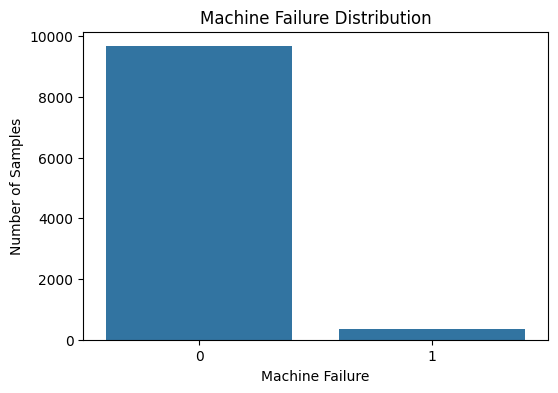

In [ ]:
plt.figure(figsize=(6,4))

sns.countplot(
    x="Machine failure",
    data=df
)

plt.title("Machine Failure Distribution")
plt.xlabel("Machine Failure")
plt.ylabel("Number of Samples")

plt.show()

# **2.8 Numerical feature distributions**

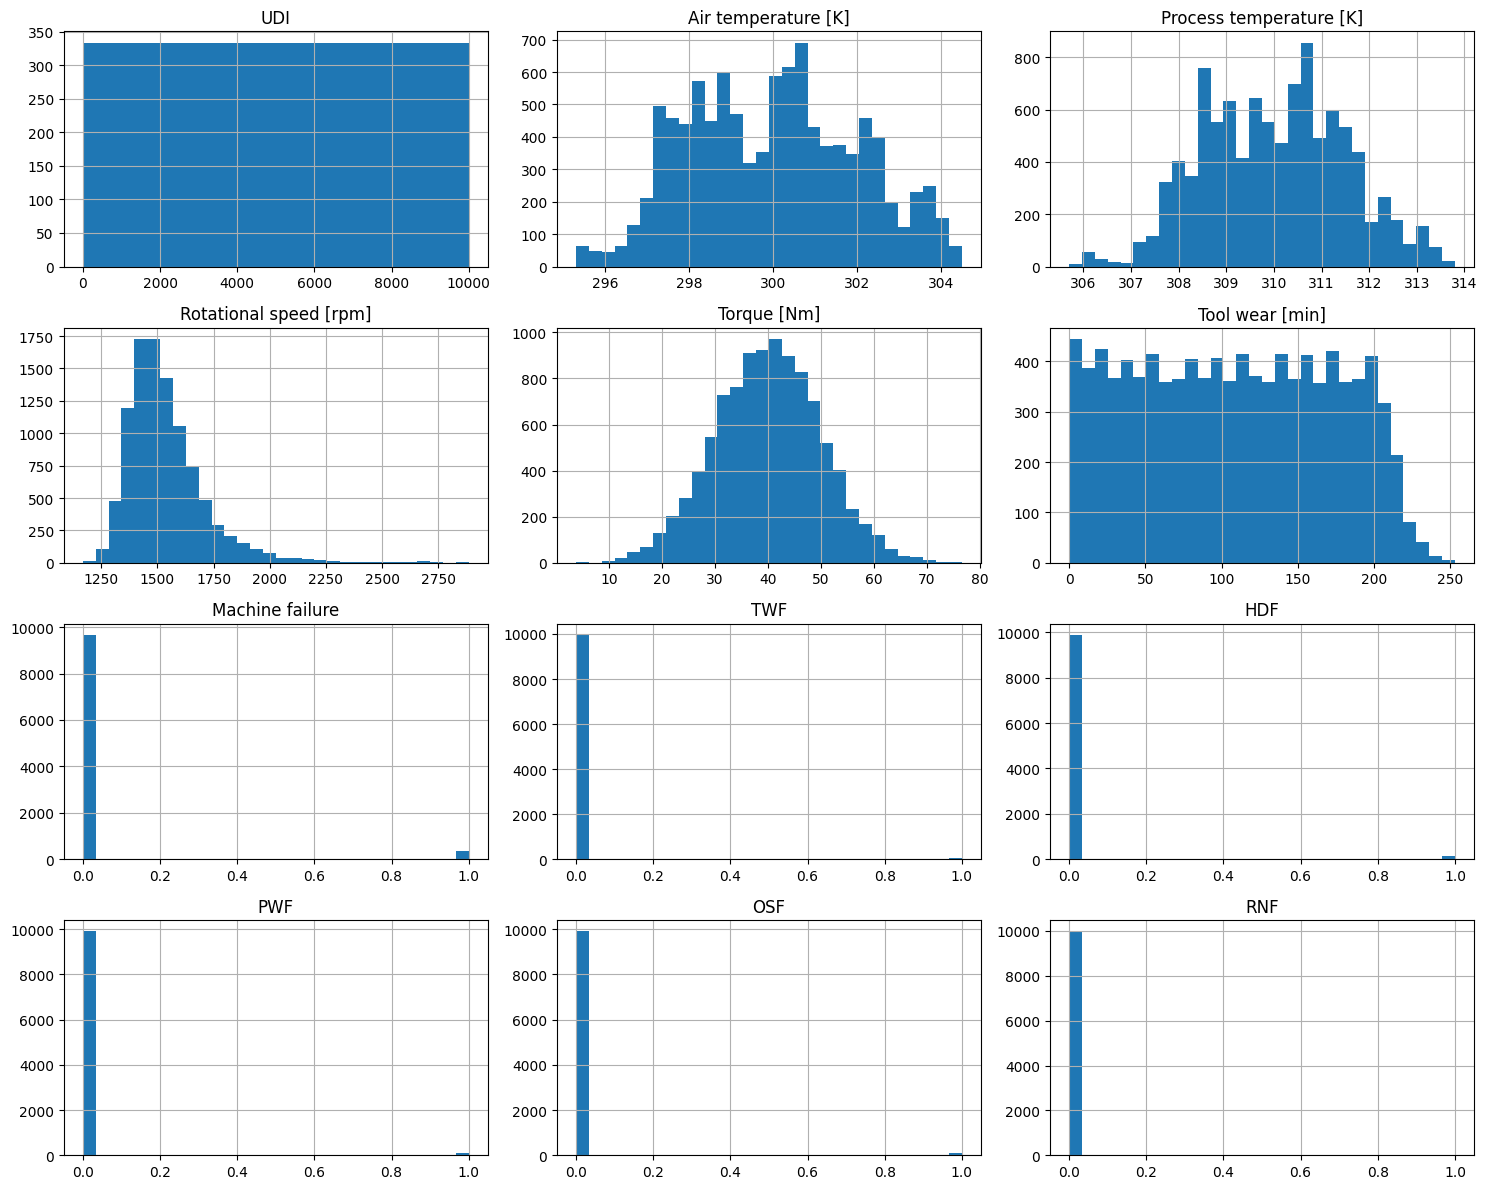

In [ ]:
numeric_columns = df.select_dtypes(
    include=np.number
).columns

df[numeric_columns].hist(
    figsize=(15,12),
    bins=30
)

plt.tight_layout()
plt.show()

# **2.9 Correlation matrix**

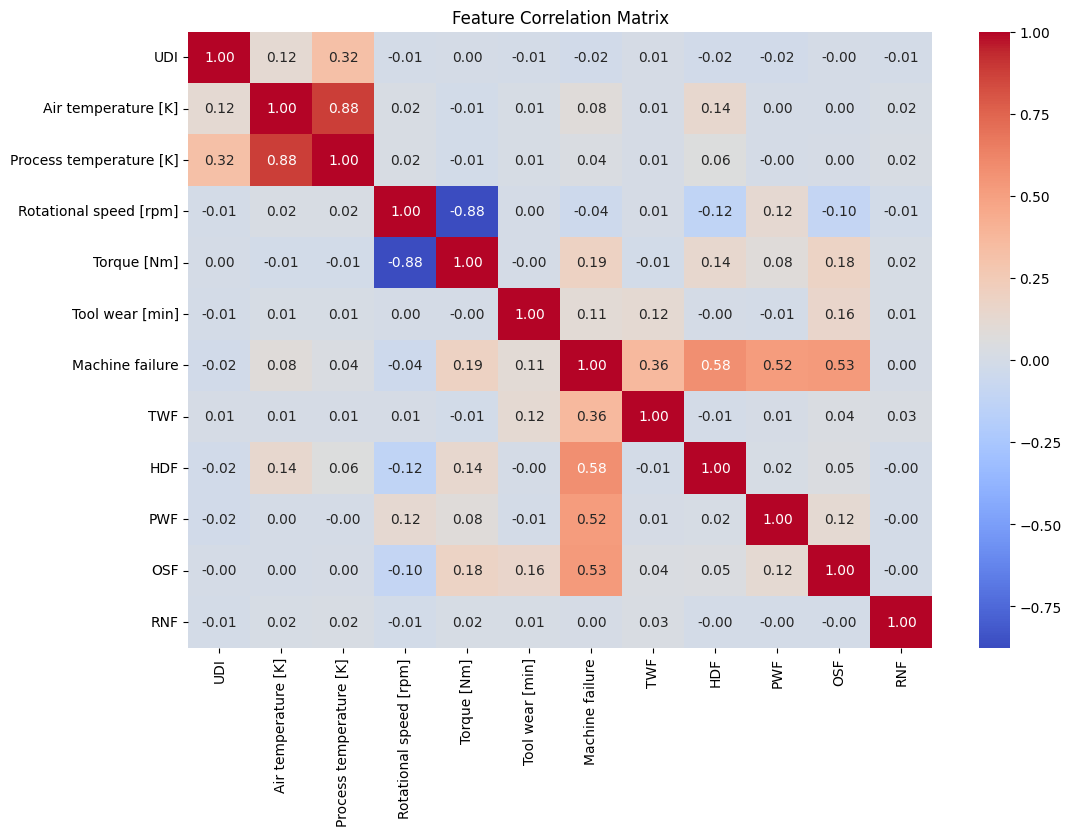

In [ ]:
plt.figure(figsize=(12,8))

correlation = df[numeric_columns].corr()

sns.heatmap(
    correlation,
    annot=True,
    fmt=".2f",
    cmap="coolwarm"
)

plt.title("Feature Correlation Matrix")

plt.show()

# **2.10 Failure by product type**

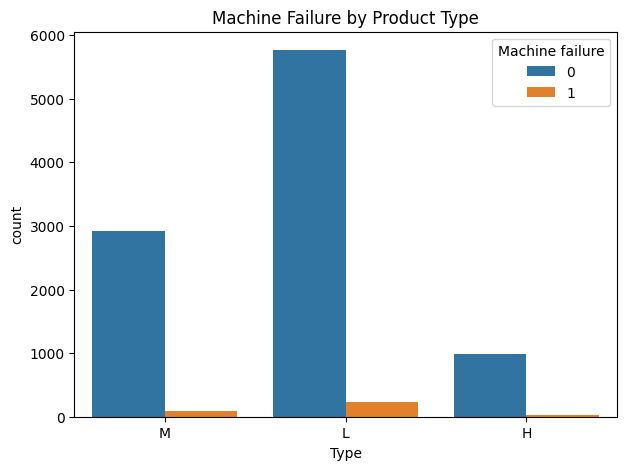

In [ ]:
plt.figure(figsize=(7,5))

sns.countplot(
    x="Type",
    hue="Machine failure",
    data=df
)

plt.title("Machine Failure by Product Type")

plt.show()

# **PART 3 — AI4I DATA PREPROCESSING**

# **3.1 Create a copy**

In [ ]:
data = df.copy()

print(data.shape)

(10000, 14)


# **3.2 Remove identifier columns**

In [ ]:
columns_to_remove = [
    "UDI",
    "Product ID"
]

data = data.drop(
    columns=columns_to_remove,
    errors="ignore"
)

print(data.columns.tolist())

['Type', 'Air temperature [K]', 'Process temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]', 'Tool wear [min]', 'Machine failure', 'TWF', 'HDF', 'PWF', 'OSF', 'RNF']


# **3.3 Separate features and target**

In [ ]:
X = data.drop(
    columns=["Machine failure"]
)

y = data["Machine failure"]

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (10000, 11)
y shape: (10000,)


# **3.4 Encode categorical feature**

In [ ]:
X = pd.get_dummies(
    X,
    columns=["Type"],
    drop_first=True
)

print(X.head())

   Air temperature [K]  Process temperature [K]  Rotational speed [rpm]  \
0                298.1                    308.6                    1551   
1                298.2                    308.7                    1408   
2                298.1                    308.5                    1498   
3                298.2                    308.6                    1433   
4                298.2                    308.7                    1408   

   Torque [Nm]  Tool wear [min]  TWF  HDF  PWF  OSF  RNF  Type_L  Type_M  
0         42.8                0    0    0    0    0    0   False    True  
1         46.3                3    0    0    0    0    0    True   False  
2         49.4                5    0    0    0    0    0    True   False  
3         39.5                7    0    0    0    0    0    True   False  
4         40.0                9    0    0    0    0    0    True   False  


# **3.5 Convert to numeric**

In [ ]:
X = X.astype(float)

# **3.6 Train-test split**

In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 8000
Testing samples: 2000


# **3.7 Feature scaling**

In [ ]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(
    X_train
)

X_test_scaled = scaler.transform(
    X_test
)

# **3.8 Save preprocessing objects**

In [ ]:
joblib.dump(
    scaler,
    os.path.join(
        PROJECT_DIR,
        "preprocessing/scaler.pkl"
    )
)

joblib.dump(
    X.columns.tolist(),
    os.path.join(
        PROJECT_DIR,
        "preprocessing/feature_columns.pkl"
    )
)

print("Preprocessing objects saved.")

Preprocessing objects saved.


# **PART 4 — BASELINE MACHINE LEARNING**

# **4.1 Logistic Regression**

In [ ]:
from sklearn.linear_model import LogisticRegression

logistic_model = LogisticRegression(
    max_iter=1000,
    class_weight="balanced",
    random_state=42
)

logistic_model.fit(
    X_train_scaled,
    y_train
)

logistic_pred = logistic_model.predict(
    X_test_scaled
)

logistic_prob = logistic_model.predict_proba(
    X_test_scaled
)[:,1]

# **4.2 Decision Tree**

In [ ]:
from sklearn.tree import DecisionTreeClassifier

tree_model = DecisionTreeClassifier(
    max_depth=8,
    class_weight="balanced",
    random_state=42
)

tree_model.fit(
    X_train,
    y_train
)

tree_pred = tree_model.predict(X_test)

tree_prob = tree_model.predict_proba(
    X_test
)[:,1]

# **PART 5 — RANDOM FOREST**

In [ ]:
from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(
    n_estimators=300,
    max_depth=None,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

rf_model.fit(
    X_train,
    y_train
)

rf_pred = rf_model.predict(X_test)

rf_prob = rf_model.predict_proba(
    X_test
)[:,1]

print("Random Forest trained.")

Random Forest trained.


# **5.1 Save Random Forest**

In [ ]:
joblib.dump(
    rf_model,
    os.path.join(
        PROJECT_DIR,
        "models/random_forest.pkl"
    )
)

print("Random Forest saved.")

Random Forest saved.


# **PART 6 — XGBOOST**

In [ ]:
from xgboost import XGBClassifier

# Make XGBoost-compatible column names
X_train_xgb = X_train.copy()
X_test_xgb = X_test.copy()

X_train_xgb.columns = [
    col.replace("[", "_")
       .replace("]", "_")
       .replace("<", "_")
       .replace(">", "_")
    for col in X_train_xgb.columns
]

X_test_xgb.columns = X_train_xgb.columns

print("New column names:")
print(X_train_xgb.columns.tolist())

New column names:
['Air temperature _K_', 'Process temperature _K_', 'Rotational speed _rpm_', 'Torque _Nm_', 'Tool wear _min_', 'TWF', 'HDF', 'PWF', 'OSF', 'RNF', 'Type_L', 'Type_M']


In [ ]:
xgb_model = XGBClassifier(
    n_estimators=300,
    max_depth=5,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    eval_metric="logloss",
    random_state=42
)

xgb_model.fit(
    X_train_xgb,
    y_train
)

xgb_pred = xgb_model.predict(
    X_test_xgb
)

xgb_prob = xgb_model.predict_proba(
    X_test_xgb
)[:, 1]

print("XGBoost trained successfully.")

XGBoost trained successfully.


# **6.1 Save XGBoost**

In [ ]:
joblib.dump(
    xgb_model,
    os.path.join(
        PROJECT_DIR,
        "models/xgboost_model.pkl"
    )
)

print("XGBoost saved successfully.")

XGBoost saved successfully.


# **PART 7 — MODEL EVALUATION**

# **7.1 Import evaluation metrics**

In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

# **7.2 Create evaluation function**

In [ ]:
def evaluate_model(
    name,
    y_true,
    predictions,
    probabilities
):

    return {
        "Model": name,
        "Accuracy": accuracy_score(
            y_true,
            predictions
        ),
        "Precision": precision_score(
            y_true,
            predictions,
            zero_division=0
        ),
        "Recall": recall_score(
            y_true,
            predictions,
            zero_division=0
        ),
        "F1 Score": f1_score(
            y_true,
            predictions,
            zero_division=0
        ),
        "ROC-AUC": roc_auc_score(
            y_true,
            probabilities
        )
    }

# **7.3 Compare all models**

In [ ]:
results = []

# Logistic Regression
results.append(
    evaluate_model(
        "Logistic Regression",
        y_test,
        logistic_pred,
        logistic_prob
    )
)

# Decision Tree
results.append(
    evaluate_model(
        "Decision Tree",
        y_test,
        tree_pred,
        tree_prob
    )
)

# Random Forest
results.append(
    evaluate_model(
        "Random Forest",
        y_test,
        rf_pred,
        rf_prob
    )
)

# XGBoost
results.append(
    evaluate_model(
        "XGBoost",
        y_test,
        xgb_pred,
        xgb_prob
    )
)

results_df = pd.DataFrame(results)

results_df

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Logistic Regression,0.9990,1.000000,0.970588,0.985075,0.972567
1,Decision Tree,0.9960,0.916667,0.970588,0.942857,0.985111
2,Random Forest,0.9985,1.000000,0.955882,0.977444,0.990976
3,XGBoost,0.9990,1.000000,0.970588,0.985075,0.996354


# **7.4 Save model comparison**

In [ ]:
results_df.to_csv(
    os.path.join(
        PROJECT_DIR,
        "results/tables/classification_results.csv"
    ),
    index=False
)

print("Classification results saved.")

Classification results saved.


# **PART 8 — CONFUSION MATRIX**

# **8.1 Generate confusion matrix**

In [ ]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(
    y_test,
    xgb_pred
)

print(cm)

[[1932    0]
 [   2   66]]


# **8.2 Plot confusion matrix**

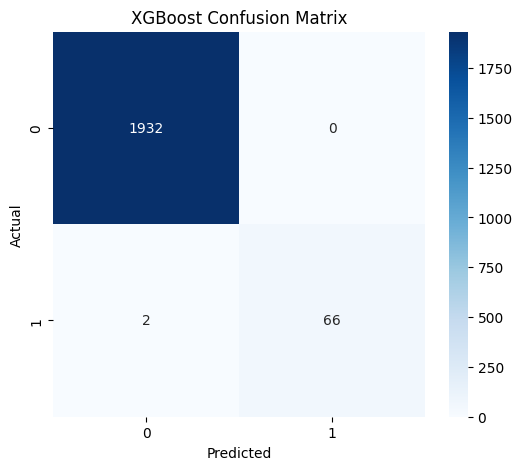

In [ ]:
plt.figure(figsize=(6,5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues"
)

plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.title(
    "XGBoost Confusion Matrix"
)

plt.show()

# **8.3 Save confusion matrix**

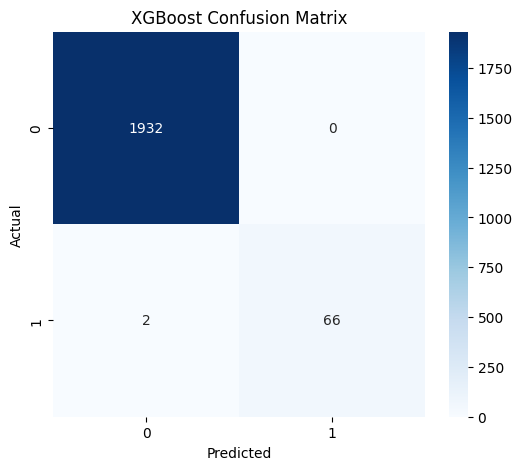

In [ ]:
plt.figure(figsize=(6,5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues"
)

plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.title(
    "XGBoost Confusion Matrix"
)

plt.savefig(
    os.path.join(
        PROJECT_DIR,
        "results/figures/xgboost_confusion_matrix.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# **PART 9 — ROC-AUC CURVE**

# **9.1 Plot ROC curves for all models**

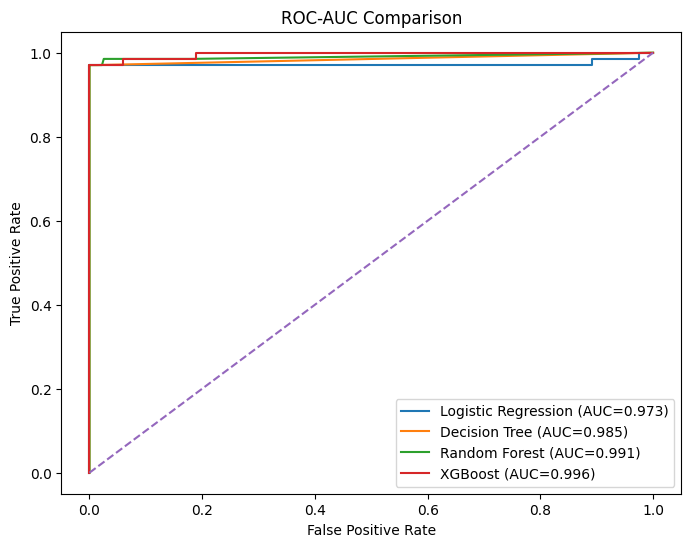

In [ ]:
from sklearn.metrics import roc_curve

models_for_roc = {
    "Logistic Regression": logistic_prob,
    "Decision Tree": tree_prob,
    "Random Forest": rf_prob,
    "XGBoost": xgb_prob
}

plt.figure(figsize=(8,6))

for name, probabilities in models_for_roc.items():

    fpr, tpr, _ = roc_curve(
        y_test,
        probabilities
    )

    auc = roc_auc_score(
        y_test,
        probabilities
    )

    plt.plot(
        fpr,
        tpr,
        label=f"{name} (AUC={auc:.3f})"
    )

plt.plot(
    [0, 1],
    [0, 1],
    "--"
)

plt.xlabel(
    "False Positive Rate"
)

plt.ylabel(
    "True Positive Rate"
)

plt.title(
    "ROC-AUC Comparison"
)

plt.legend()

plt.show()

# **9.2 Save ROC curve**

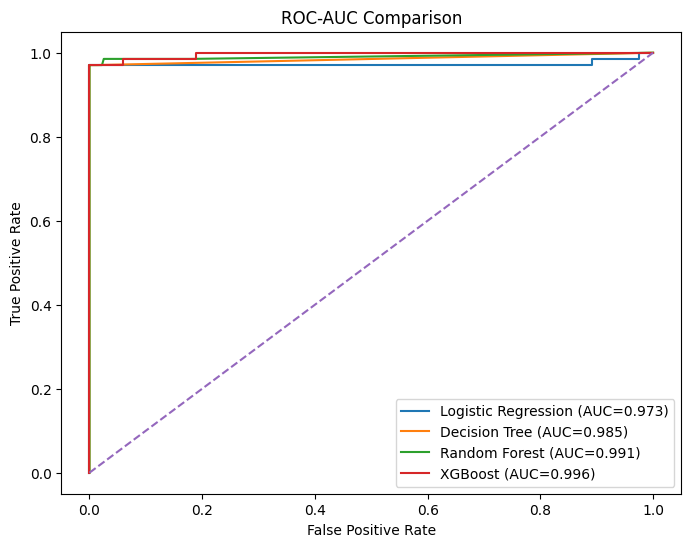

In [ ]:
plt.figure(figsize=(8,6))

for name, probabilities in models_for_roc.items():

    fpr, tpr, _ = roc_curve(
        y_test,
        probabilities
    )

    auc = roc_auc_score(
        y_test,
        probabilities
    )

    plt.plot(
        fpr,
        tpr,
        label=f"{name} (AUC={auc:.3f})"
    )

plt.plot(
    [0, 1],
    [0, 1],
    "--"
)

plt.xlabel(
    "False Positive Rate"
)

plt.ylabel(
    "True Positive Rate"
)

plt.title(
    "ROC-AUC Comparison"
)

plt.legend()

plt.savefig(
    os.path.join(
        PROJECT_DIR,
        "results/figures/roc_comparison.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# **PART 10 — FEATURE IMPORTANCE**

# **10.1 Calculate feature importance**

In [ ]:
importance = pd.Series(
    xgb_model.feature_importances_,
    index=X_train_xgb.columns
).sort_values(
    ascending=False
)

print(importance)

HDF                        0.308810
PWF                        0.228661
OSF                        0.210639
TWF                        0.163848
Torque _Nm_                0.022306
Rotational speed _rpm_     0.020990
Tool wear _min_            0.018185
Air temperature _K_        0.012557
Type_L                     0.005129
Process temperature _K_    0.004657
Type_M                     0.004217
RNF                        0.000000
dtype: float32


# **10.2 Display top 10 features**

In [ ]:
print(
    importance.head(10)
)

HDF                        0.308810
PWF                        0.228661
OSF                        0.210639
TWF                        0.163848
Torque _Nm_                0.022306
Rotational speed _rpm_     0.020990
Tool wear _min_            0.018185
Air temperature _K_        0.012557
Type_L                     0.005129
Process temperature _K_    0.004657
dtype: float32


# **10.3 Plot feature importance**

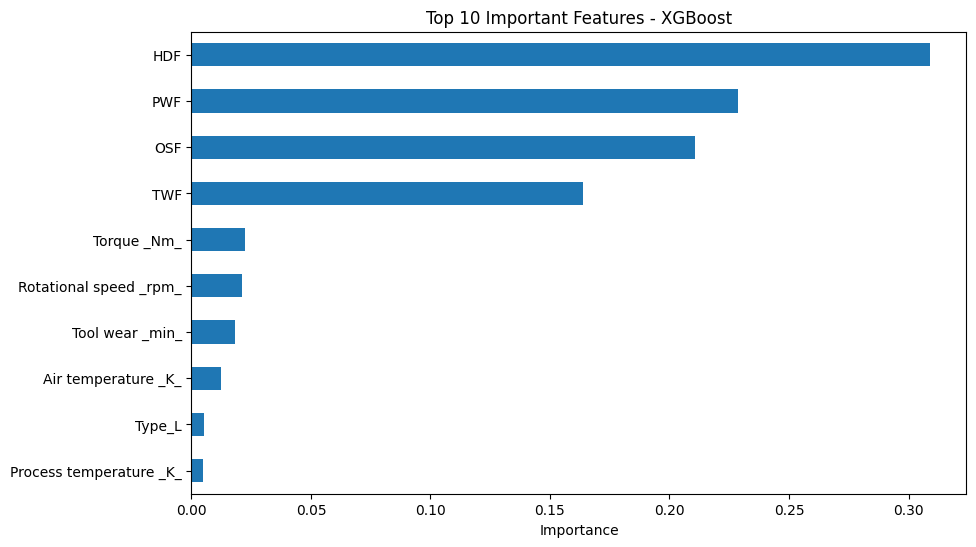

In [ ]:
plt.figure(figsize=(10,6))

importance.head(10).sort_values().plot(
    kind="barh"
)

plt.title(
    "Top 10 Important Features - XGBoost"
)

plt.xlabel(
    "Importance"
)

plt.show()

# **10.4 Save feature importance graph**

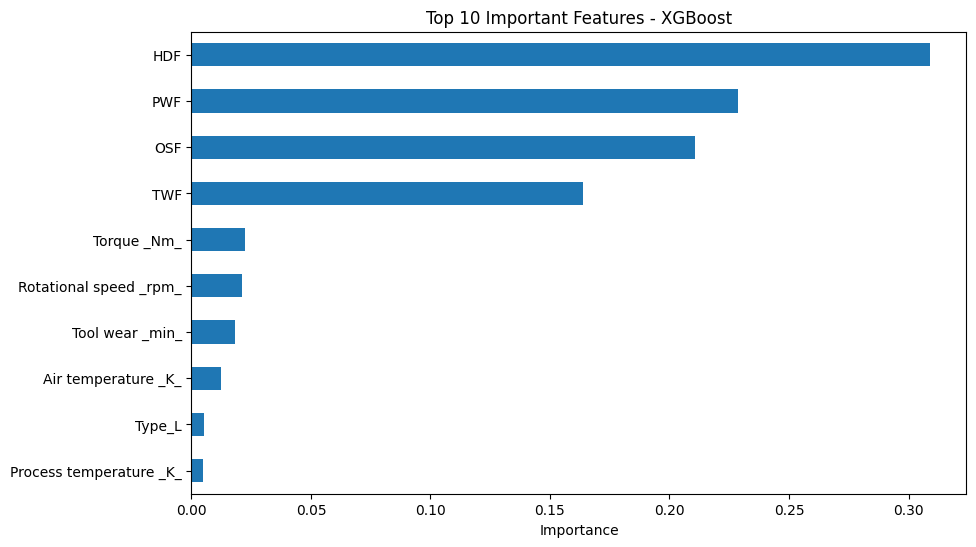

In [ ]:
plt.figure(figsize=(10,6))

importance.head(10).sort_values().plot(
    kind="barh"
)

plt.title(
    "Top 10 Important Features - XGBoost"
)

plt.xlabel(
    "Importance"
)

plt.savefig(
    os.path.join(
        PROJECT_DIR,
        "results/figures/xgboost_feature_importance.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# **PART 11 — EXPLAINABLE AI USING SHAP**

# **11.1 Import SHAP**

In [ ]:
import shap

print(
    "SHAP version:",
    shap.__version__
)

SHAP version: 0.52.0


# **11.2 Create SHAP explainer**

In [ ]:
explainer = shap.TreeExplainer(
    xgb_model
)

shap_values = explainer.shap_values(
    X_test_xgb
)

print("SHAP values generated successfully.")

SHAP values generated successfully.


# **11.3 SHAP summary plot**

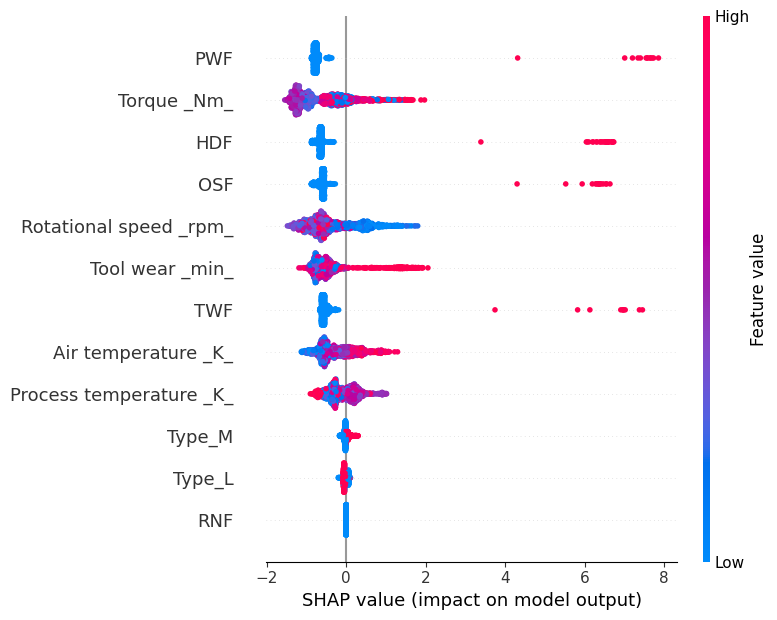

In [ ]:
shap.summary_plot(
    shap_values,
    X_test_xgb,
    show=True
)

# **11.4 Save SHAP summary**

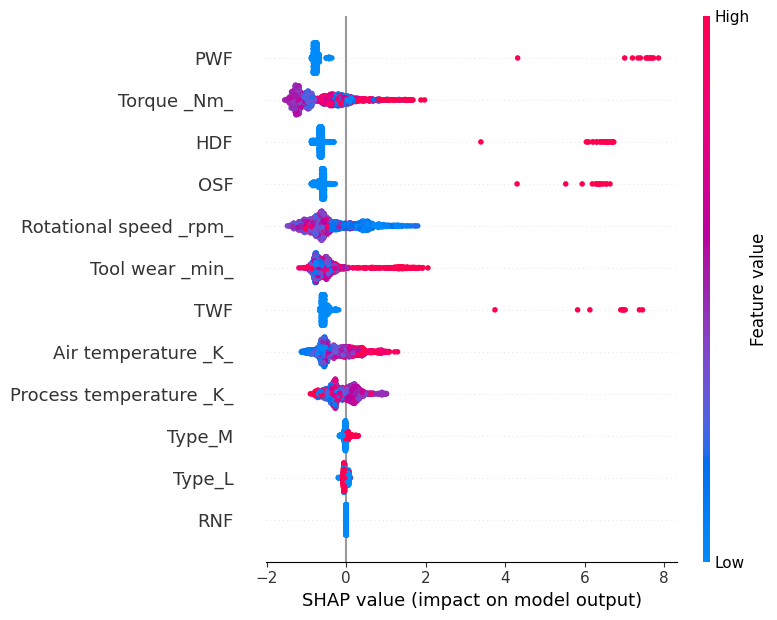

In [ ]:
shap.summary_plot(
    shap_values,
    X_test_xgb,
    show=False
)

plt.savefig(
    os.path.join(
        PROJECT_DIR,
        "results/figures/shap_summary.png"
    ),
    dpi=300,
    bbox_inches="tight"
)


# **PART 12 — SHAP WATERFALL FOR ONE MACHINE**

# **12.1 Select one test machine**

In [ ]:
sample_index = 0

sample = X_test_xgb.iloc[
    [sample_index]
]

print(sample)

      Air temperature _K_  Process temperature _K_  Rotational speed _rpm_  \
2997                300.5                    309.8                  1345.0   

      Torque _Nm_  Tool wear _min_  TWF  HDF  PWF  OSF  RNF  Type_L  Type_M  
2997         62.7            153.0  0.0  0.0  0.0  0.0  0.0     1.0     0.0  


# **12.2 Generate SHAP explanation**

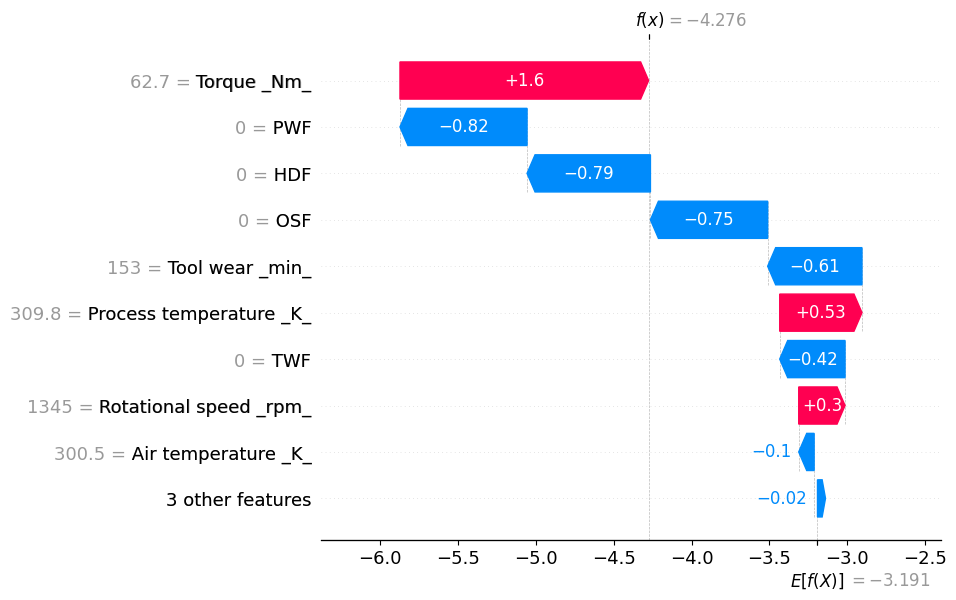

In [ ]:
sample_shap = explainer(
    sample
)

shap.plots.waterfall(
    sample_shap[0]
)

# **PART 13 — ANOMALY DETECTION**

# **13.1 Import Isolation Forest**

In [ ]:
from sklearn.ensemble import IsolationForest

# **13.2 Train anomaly detection model**

In [ ]:
anomaly_model = IsolationForest(
    n_estimators=200,
    contamination=0.05,
    random_state=42
)

anomaly_model.fit(
    X_train_scaled
)

print(
    "Anomaly detection model trained."
)

Anomaly detection model trained.


# **13.3 Predict anomalies**

In [ ]:
anomaly_predictions = anomaly_model.predict(
    X_test_scaled
)

print(
    np.unique(
        anomaly_predictions,
        return_counts=True
    )
)

(array([-1,  1]), array([  98, 1902]))


# **13.4 Convert to easier labels**

In [ ]:
anomaly_labels = np.where(
    anomaly_predictions == -1,
    1,
    0
)

print(
    pd.Series(
        anomaly_labels
    ).value_counts()
)

0    1902
1      98
Name: count, dtype: int64


# **13.5 Save anomaly model**

In [ ]:
joblib.dump(
    anomaly_model,
    os.path.join(
        PROJECT_DIR,
        "models/isolation_forest.pkl"
    )
)

print(
    "Isolation Forest model saved."
)

Isolation Forest model saved.


# **PART 14 — K-MEANS MACHINE OPERATING STATES**

# **14.1 Import K-Means**

In [ ]:
from sklearn.cluster import KMeans

# **14.2 Train K-Means**

In [ ]:
kmeans = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)

clusters = kmeans.fit_predict(
    X_train_scaled
)

print(
    pd.Series(
        clusters
    ).value_counts()
)

0    5550
2    2364
1      86
Name: count, dtype: int64


# **PART 15 — PCA VISUALIZATION OF MACHINE STATES**

# **15.1 Reduce to 2 dimensions**

In [ ]:
from sklearn.decomposition import PCA

pca = PCA(
    n_components=2,
    random_state=42
)

X_pca = pca.fit_transform(
    X_train_scaled
)

print(
    "PCA shape:",
    X_pca.shape
)

PCA shape: (8000, 2)


# **15.2 Plot clusters**

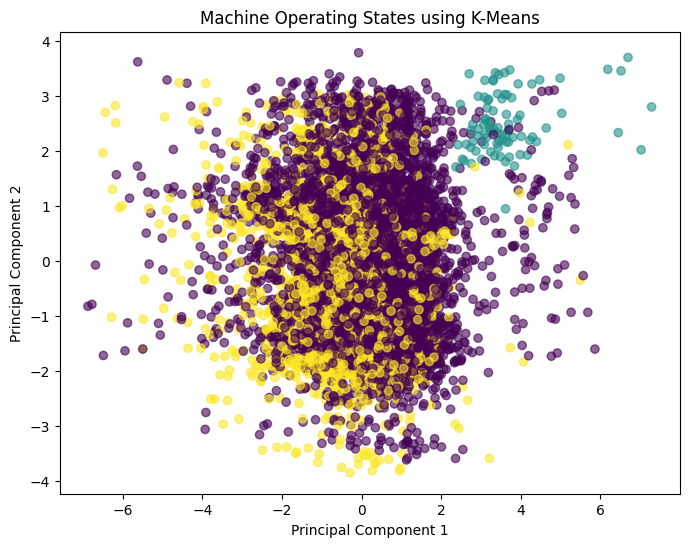

In [ ]:
plt.figure(figsize=(8,6))

plt.scatter(
    X_pca[:,0],
    X_pca[:,1],
    c=clusters,
    alpha=0.6
)

plt.xlabel(
    "Principal Component 1"
)

plt.ylabel(
    "Principal Component 2"
)

plt.title(
    "Machine Operating States using K-Means"
)

plt.show()

# **15.3 Save plot**

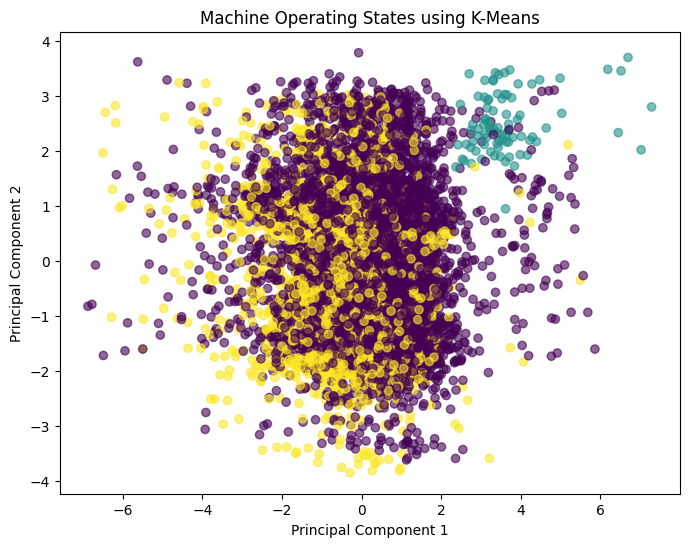

In [ ]:
plt.figure(figsize=(8,6))

plt.scatter(
    X_pca[:,0],
    X_pca[:,1],
    c=clusters,
    alpha=0.6
)

plt.xlabel(
    "Principal Component 1"
)

plt.ylabel(
    "Principal Component 2"
)

plt.title(
    "Machine Operating States using K-Means"
)

plt.savefig(
    os.path.join(
        PROJECT_DIR,
        "results/figures/kmeans_machine_states.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# **PART 16 — SAVE PROCESSED AI4I DATA**

In [ ]:
processed_ai4i = data.copy()

processed_ai4i.to_csv(
    os.path.join(
        PROJECT_DIR,
        "datasets/processed/ai4i_processed.csv"
    ),
    index=False
)

print(
    "Processed AI4I dataset saved."
)

Processed AI4I dataset saved.


# **PART 17 — MACHINE FAILURE PREDICTION FUNCTION**

# **17.1 Prediction function**

In [ ]:
def predict_machine_failure(input_data):

    input_df = pd.DataFrame(
        [input_data]
    )

    # Convert categorical feature
    input_df = pd.get_dummies(
        input_df,
        columns=["Type"],
        drop_first=True
    )

    # Make columns same as training data
    input_df = input_df.reindex(
        columns=X.columns,
        fill_value=0
    )

    # Clean column names for XGBoost
    input_df.columns = [
        col.replace("[", "_")
           .replace("]", "_")
           .replace("<", "_")
           .replace(">", "_")
        for col in input_df.columns
    ]

    # Prediction
    probability = xgb_model.predict_proba(
        input_df
    )[0][1]

    prediction = int(
        probability >= 0.5
    )

    return prediction, probability

# **PART 18 — TEST MACHINE FAILURE PREDICTION**

In [ ]:
sample_machine = {
    "Air temperature [K]": 300,
    "Process temperature [K]": 310,
    "Rotational speed [rpm]": 1500,
    "Torque [Nm]": 45,
    "Tool wear [min]": 100,
    "Type": "M"
}

In [ ]:
prediction, probability = predict_machine_failure(
    sample_machine
)

print(
    "Prediction:",
    prediction
)

print(
    "Failure probability:",
    round(
        probability * 100,
        2
    ),
    "%"
)

Prediction: 0
Failure probability: 0.48 %


# **PART 19 — MACHINE HEALTH STATUS**

In [ ]:
def machine_health_report(
    probability
):

    if probability < 0.30:

        status = "NORMAL"

    elif probability < 0.70:

        status = "WARNING"

    else:

        status = "CRITICAL"

    return status

In [ ]:
status = machine_health_report(
    probability
)

print(
    "Machine Status:",
    status
)

Machine Status: NORMAL


# **PART 20 — ROOT-CAUSE ANALYSIS**

# **20.1 Root-cause function**

In [ ]:
def get_root_cause(
    explainer,
    sample
):

    shap_explanation = explainer(
        sample
    )

    contributions = pd.Series(
        shap_explanation.values[0],
        index=sample.columns
    )

    contributions = contributions.sort_values(
        key=abs,
        ascending=False
    )

    return contributions

# **20.2 Get top contributing factors**

In [ ]:
sample = X_test_xgb.iloc[
    [0]
]

root_causes = get_root_cause(
    explainer,
    sample
)

print(
    root_causes.head(5)
)

Torque _Nm_        1.597921
PWF               -0.816666
HDF               -0.792874
OSF               -0.753418
Tool wear _min_   -0.606013
dtype: float32


# **PART 21 — MAINTENANCE RECOMMENDATION**

# **21.1 Recommendation function**

In [ ]:
def maintenance_recommendation(
    failure_probability
):

    if failure_probability >= 0.70:

        recommendation = (
            "HIGH RISK: Schedule machine "
            "inspection and maintenance."
        )

    elif failure_probability >= 0.30:

        recommendation = (
            "MEDIUM RISK: Increase monitoring "
            "and inspect important parameters."
        )

    else:

        recommendation = (
            "LOW RISK: Continue normal "
            "machine monitoring."
        )

    return recommendation

# **21.2 Generate recommendation**

In [ ]:
recommendation = maintenance_recommendation(
    probability
)

print(
    recommendation
)

LOW RISK: Continue normal machine monitoring.


# **PART 22 — FINAL MACHINE HEALTH REPORT**

In [ ]:
def generate_machine_report(
    failure_probability,
    anomaly
):

    if failure_probability >= 0.70:

        risk = "CRITICAL"

    elif failure_probability >= 0.30:

        risk = "WARNING"

    else:

        risk = "NORMAL"

    report = {

        "Failure Probability (%)":
            round(
                failure_probability * 100,
                2
            ),

        "Risk Level":
            risk,

        "Anomaly Status":
            "ANOMALY"
            if anomaly == 1
            else "NORMAL"
    }

    return report

# **PART 23 — GENERATE SAMPLE REPORT**

In [ ]:


report = generate_machine_report(
    float(probability),
    int(anomaly_labels[0])
)

print(
    json.dumps(
        report,
        indent=4
    )
)

{
    "Failure Probability (%)": 0.48,
    "Risk Level": "NORMAL",
    "Anomaly Status": "NORMAL"
}


# **PART 24 — SAVE REPORT**

In [ ]:
report_path = os.path.join(
    PROJECT_DIR,
    "results/predictions/sample_machine_report.json"
)

with open(
    report_path,
    "w"
) as f:

    json.dump(
        report,
        f,
        indent=4
    )

print(
    "Report saved:"
)

print(
    report_path
)

Report saved:
/content/drive/MyDrive/Smart_Maintenance_AI/results/predictions/sample_machine_report.json


# **PART 25 — FINAL AI4I MODEL COMPARISON**

In [ ]:
final_comparison = pd.DataFrame({

    "Component": [
        "Failure Prediction",
        "Anomaly Detection",
        "Operating State Detection"
    ],

    "Model": [
        "XGBoost",
        "Isolation Forest",
        "K-Means"
    ],

    "Purpose": [
        "Predict machine failure risk",
        "Detect unusual machine behavior",
        "Identify machine operating patterns"
    ]
})

final_comparison

,Component,Model,Purpose
0,Failure Prediction,XGBoost,Predict machine failure risk
1,Anomaly Detection,Isolation Forest,Detect unusual machine behavior
2,Operating State Detection,K-Means,Identify machine operating patterns


In [ ]:
final_comparison.to_csv(
    os.path.join(
        PROJECT_DIR,
        "results/tables/final_ai4i_components.csv"
    ),
    index=False
)

print(
    "Final AI4I comparison saved."
)

Final AI4I comparison saved.


# **PART 26 — SAVE AI4I CHECKPOINT**

In [ ]:
status = {

    "project":
        "Explainable Multimodal AI for Predictive Maintenance",

    "current_stage":
        "AI4I module completed",

    "completed": [

        "AI4I dataset loading",

        "Exploratory Data Analysis",

        "Data preprocessing",

        "Train-test split",

        "Logistic Regression",

        "Decision Tree",

        "Random Forest",

        "XGBoost",

        "Model evaluation",

        "Confusion Matrix",

        "ROC-AUC",

        "Feature importance",

        "SHAP explainability",

        "Isolation Forest anomaly detection",

        "K-Means clustering",

        "Machine failure prediction",

        "Root-cause analysis",

        "Maintenance recommendation"

    ],

    "next_stage":
        "NASA C-MAPSS RUL prediction"

}

status_path = os.path.join(
    PROJECT_DIR,
    "checkpoints/project_status.json"
)

with open(
    status_path,
    "w"
) as f:

    json.dump(
        status,
        f,
        indent=4
    )

print(
    "AI4I checkpoint saved successfully."
)

AI4I checkpoint saved successfully.


# **PART 27 — CHECK EVERYTHING WAS SAVED**

In [ ]:
print("MODELS:")
print(
    os.listdir(
        os.path.join(
            PROJECT_DIR,
            "models"
        )
    )
)

print("\nPREPROCESSING:")
print(
    os.listdir(
        os.path.join(
            PROJECT_DIR,
            "preprocessing"
        )
    )
)

print("\nRESULT TABLES:")
print(
    os.listdir(
        os.path.join(
            PROJECT_DIR,
            "results/tables"
        )
    )
)

print("\nFIGURES:")
print(
    os.listdir(
        os.path.join(
            PROJECT_DIR,
            "results/figures"
        )
    )
)

MODELS:
['random_forest.pkl', 'xgboost_model.pkl', 'isolation_forest.pkl']

PREPROCESSING:
['scaler.pkl', 'feature_columns.pkl']

RESULT TABLES:
['classification_results.csv', 'final_ai4i_components.csv']

FIGURES:
['xgboost_confusion_matrix.png', 'roc_comparison.png', 'xgboost_feature_importance.png', 'shap_summary.png', 'kmeans_machine_states.png']


# **PART 28 — NASA C-MAPSS DATASET**

# **28.1 Locate ZIP**

In [ ]:
CMAPSS_DIR = os.path.join(
    PROJECT_DIR,
    "datasets/raw/C-MAPSS"
)

cmapss_zips = [
    f for f in os.listdir(CMAPSS_DIR)
    if f.lower().endswith(".zip")
]

print(cmapss_zips)

['CMAPSSData.zip']


# **28.2 Extract**

In [ ]:
CMAPSS_ZIP = os.path.join(
    CMAPSS_DIR,
    cmapss_zips[0]
)

CMAPSS_EXTRACTED = os.path.join(
    CMAPSS_DIR,
    "extracted"
)

os.makedirs(
    CMAPSS_EXTRACTED,
    exist_ok=True
)

with zipfile.ZipFile(
    CMAPSS_ZIP,
    "r"
) as zip_ref:

    zip_ref.extractall(
        CMAPSS_EXTRACTED
    )

print("C-MAPSS extracted.")

C-MAPSS extracted.


# **PART 29 — FIND C-MAPSS FILES**

In [ ]:
for root, dirs, files in os.walk(
    CMAPSS_EXTRACTED
):

    for file in files:

        print(
            os.path.join(
                root,
                file
            )
        )

/content/drive/MyDrive/Smart_Maintenance_AI/datasets/raw/C-MAPSS/extracted/Damage Propagation Modeling.pdf
/content/drive/MyDrive/Smart_Maintenance_AI/datasets/raw/C-MAPSS/extracted/readme.txt
/content/drive/MyDrive/Smart_Maintenance_AI/datasets/raw/C-MAPSS/extracted/RUL_FD001.txt
/content/drive/MyDrive/Smart_Maintenance_AI/datasets/raw/C-MAPSS/extracted/RUL_FD002.txt
/content/drive/MyDrive/Smart_Maintenance_AI/datasets/raw/C-MAPSS/extracted/RUL_FD003.txt
/content/drive/MyDrive/Smart_Maintenance_AI/datasets/raw/C-MAPSS/extracted/RUL_FD004.txt
/content/drive/MyDrive/Smart_Maintenance_AI/datasets/raw/C-MAPSS/extracted/test_FD001.txt
/content/drive/MyDrive/Smart_Maintenance_AI/datasets/raw/C-MAPSS/extracted/test_FD002.txt
/content/drive/MyDrive/Smart_Maintenance_AI/datasets/raw/C-MAPSS/extracted/test_FD003.txt
/content/drive/MyDrive/Smart_Maintenance_AI/datasets/raw/C-MAPSS/extracted/test_FD004.txt
/content/drive/MyDrive/Smart_Maintenance_AI/datasets/raw/C-MAPSS/extracted/train_FD001.txt


# **PART 30 — LOAD FD001**

In [ ]:
train_files = []

for root, dirs, files in os.walk(
    CMAPSS_EXTRACTED
):

    for file in files:

        if file.startswith(
            "train_FD001"
        ):

            train_files.append(
                os.path.join(
                    root,
                    file
                )
            )

print(train_files)

['/content/drive/MyDrive/Smart_Maintenance_AI/datasets/raw/C-MAPSS/extracted/train_FD001.txt']


# **30.1 Load training data**

In [ ]:
train_path = train_files[0]

train_cmapss = pd.read_csv(
    train_path,
    sep=r"\s+",
    header=None
)

print(train_cmapss.shape)

train_cmapss.head()

(20631, 26)


,0,1,2,3,4,5,6,7,8,9,...,16,17,18,19,20,21,22,23,24,25
0,1,1,-0.0007,-0.0004,100.0,518.67,641.82,1589.70,1400.60,14.62,...,521.66,2388.02,8138.62,8.4195,0.03,392,2388,100.0,39.06,23.4190
1,1,2,0.0019,-0.0003,100.0,518.67,642.15,1591.82,1403.14,14.62,...,522.28,2388.07,8131.49,8.4318,0.03,392,2388,100.0,39.00,23.4236
2,1,3,-0.0043,0.0003,100.0,518.67,642.35,1587.99,1404.20,14.62,...,522.42,2388.03,8133.23,8.4178,0.03,390,2388,100.0,38.95,23.3442
3,1,4,0.0007,0.0000,100.0,518.67,642.35,1582.79,1401.87,14.62,...,522.86,2388.08,8133.83,8.3682,0.03,392,2388,100.0,38.88,23.3739
4,1,5,-0.0019,-0.0002,100.0,518.67,642.37,1582.85,1406.22,14.62,...,522.19,2388.04,8133.80,8.4294,0.03,393,2388,100.0,38.90,23.4044


# **PART 31 — NAME C-MAPSS COLUMNS**

In [ ]:
columns = [
    "engine_id",
    "cycle",
    "setting_1",
    "setting_2",
    "setting_3"
]

sensor_columns = [
    f"sensor_{i}"
    for i in range(1, 22)
]

train_cmapss.columns = (
    columns + sensor_columns
)

train_cmapss.head()

,engine_id,cycle,setting_1,setting_2,setting_3,sensor_1,sensor_2,sensor_3,sensor_4,sensor_5,...,sensor_12,sensor_13,sensor_14,sensor_15,sensor_16,sensor_17,sensor_18,sensor_19,sensor_20,sensor_21
0,1,1,-0.0007,-0.0004,100.0,518.67,641.82,1589.70,1400.60,14.62,...,521.66,2388.02,8138.62,8.4195,0.03,392,2388,100.0,39.06,23.4190
1,1,2,0.0019,-0.0003,100.0,518.67,642.15,1591.82,1403.14,14.62,...,522.28,2388.07,8131.49,8.4318,0.03,392,2388,100.0,39.00,23.4236
2,1,3,-0.0043,0.0003,100.0,518.67,642.35,1587.99,1404.20,14.62,...,522.42,2388.03,8133.23,8.4178,0.03,390,2388,100.0,38.95,23.3442
3,1,4,0.0007,0.0000,100.0,518.67,642.35,1582.79,1401.87,14.62,...,522.86,2388.08,8133.83,8.3682,0.03,392,2388,100.0,38.88,23.3739
4,1,5,-0.0019,-0.0002,100.0,518.67,642.37,1582.85,1406.22,14.62,...,522.19,2388.04,8133.80,8.4294,0.03,393,2388,100.0,38.90,23.4044


# **PART 32 — CREATE RUL LABEL**

In [ ]:
max_cycles = train_cmapss.groupby(
    "engine_id"
)["cycle"].transform("max")

train_cmapss["RUL"] = (
    max_cycles -
    train_cmapss["cycle"]
)

train_cmapss.head()

,engine_id,cycle,setting_1,setting_2,setting_3,sensor_1,sensor_2,sensor_3,sensor_4,sensor_5,...,sensor_13,sensor_14,sensor_15,sensor_16,sensor_17,sensor_18,sensor_19,sensor_20,sensor_21,RUL
0,1,1,-0.0007,-0.0004,100.0,518.67,641.82,1589.70,1400.60,14.62,...,2388.02,8138.62,8.4195,0.03,392,2388,100.0,39.06,23.4190,191
1,1,2,0.0019,-0.0003,100.0,518.67,642.15,1591.82,1403.14,14.62,...,2388.07,8131.49,8.4318,0.03,392,2388,100.0,39.00,23.4236,190
2,1,3,-0.0043,0.0003,100.0,518.67,642.35,1587.99,1404.20,14.62,...,2388.03,8133.23,8.4178,0.03,390,2388,100.0,38.95,23.3442,189
3,1,4,0.0007,0.0000,100.0,518.67,642.35,1582.79,1401.87,14.62,...,2388.08,8133.83,8.3682,0.03,392,2388,100.0,38.88,23.3739,188
4,1,5,-0.0019,-0.0002,100.0,518.67,642.37,1582.85,1406.22,14.62,...,2388.04,8133.80,8.4294,0.03,393,2388,100.0,38.90,23.4044,187


# **PART 33 — RUL VISUALIZATION**

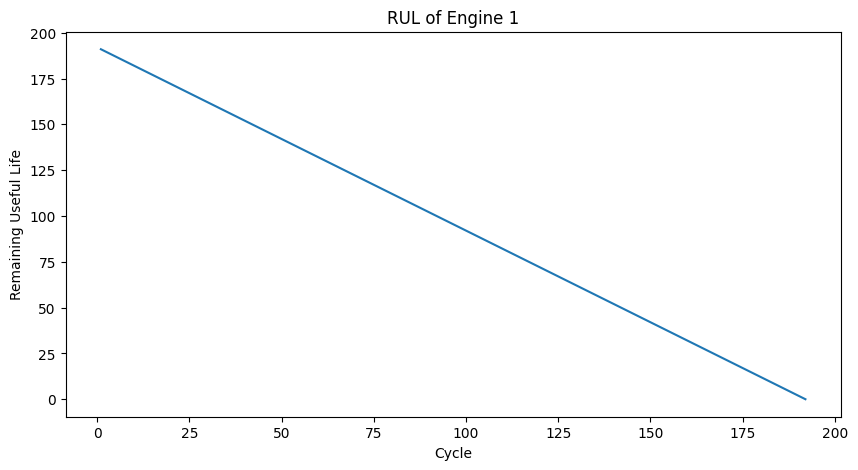

In [ ]:
engine_id = 1

engine_data = train_cmapss[
    train_cmapss["engine_id"] == engine_id
]

plt.figure(figsize=(10,5))

plt.plot(
    engine_data["cycle"],
    engine_data["RUL"]
)

plt.xlabel("Cycle")
plt.ylabel("Remaining Useful Life")

plt.title(
    f"RUL of Engine {engine_id}"
)

plt.show()

# **PART 34 — C-MAPSS PREPROCESSING**

In [ ]:
sensor_variance = train_cmapss[
    sensor_columns
].var()

useful_sensors = sensor_variance[
    sensor_variance > 0
].index.tolist()

print(
    "Useful sensors:",
    useful_sensors
)

Useful sensors: ['sensor_1', 'sensor_2', 'sensor_3', 'sensor_4', 'sensor_5', 'sensor_6', 'sensor_7', 'sensor_8', 'sensor_9', 'sensor_10', 'sensor_11', 'sensor_12', 'sensor_13', 'sensor_14', 'sensor_15', 'sensor_16', 'sensor_17', 'sensor_20', 'sensor_21']


# **PART 35 — SCALE C-MAPSS**

In [ ]:
from sklearn.preprocessing import MinMaxScaler

rul_scaler = MinMaxScaler()

train_cmapss[
    useful_sensors
] = rul_scaler.fit_transform(
    train_cmapss[
        useful_sensors
    ]
)

In [ ]:
joblib.dump(
    rul_scaler,
    os.path.join(
        PROJECT_DIR,
        "preprocessing/rul_scaler.pkl"
    )
)

['/content/drive/MyDrive/Smart_Maintenance_AI/preprocessing/rul_scaler.pkl']

# **PART 36 — CREATE SEQUENCES**

In [ ]:
def create_sequences(
    dataframe,
    sequence_length=30
):

    X = []
    y = []

    for engine_id in dataframe[
        "engine_id"
    ].unique():

        engine = dataframe[
            dataframe["engine_id"] == engine_id
        ]

        values = engine[
            useful_sensors
        ].values

        rul_values = engine[
            "RUL"
        ].values

        for i in range(
            len(engine) - sequence_length
        ):

            X.append(
                values[
                    i:i+sequence_length
                ]
            )

            y.append(
                rul_values[
                    i+sequence_length
                ]
            )

    return np.array(X), np.array(y)

# **PART 37 — CREATE LSTM DATA**

In [ ]:
SEQUENCE_LENGTH = 30

X_rul, y_rul = create_sequences(
    train_cmapss,
    SEQUENCE_LENGTH
)

print("X shape:", X_rul.shape)
print("y shape:", y_rul.shape)

X shape: (17631, 30, 19)
y shape: (17631,)


# **PART 38 — TRAIN/VALIDATION SPLIT**

In [ ]:
from sklearn.model_selection import train_test_split

X_rul_train, X_rul_val, y_rul_train, y_rul_val = train_test_split(
    X_rul,
    y_rul,
    test_size=0.20,
    random_state=42
)

print(
    X_rul_train.shape,
    X_rul_val.shape
)

(14104, 30, 19) (3527, 30, 19)


# **PART 39 — LSTM MODEL**

In [ ]:
import torch
import torch.nn as nn

device = torch.device(
    "cuda" if torch.cuda.is_available()
    else "cpu"
)

print("Device:", device)

Device: cuda


In [ ]:
class LSTMModel(nn.Module):

    def __init__(
        self,
        input_size,
        hidden_size=64
    ):

        super().__init__()

        self.lstm = nn.LSTM(
            input_size=input_size,
            hidden_size=hidden_size,
            batch_first=True
        )

        self.fc = nn.Linear(
            hidden_size,
            1
        )

    def forward(self, x):

        output, _ = self.lstm(x)

        last_output = output[:, -1, :]

        return self.fc(
            last_output
        )

# **PART 40 — PREPARE PYTORCH DATA**

In [ ]:
from torch.utils.data import (
    TensorDataset,
    DataLoader
)

X_train_tensor = torch.tensor(
    X_rul_train,
    dtype=torch.float32
)

y_train_tensor = torch.tensor(
    y_rul_train,
    dtype=torch.float32
).view(-1,1)

X_val_tensor = torch.tensor(
    X_rul_val,
    dtype=torch.float32
)

y_val_tensor = torch.tensor(
    y_rul_val,
    dtype=torch.float32
).view(-1,1)

In [ ]:
train_dataset = TensorDataset(
    X_train_tensor,
    y_train_tensor
)

val_dataset = TensorDataset(
    X_val_tensor,
    y_val_tensor
)

train_loader = DataLoader(
    train_dataset,
    batch_size=64,
    shuffle=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=64,
    shuffle=False
)

# **PART 41 — CREATE LSTM**

In [ ]:
lstm_model = LSTMModel(
    input_size=len(useful_sensors),
    hidden_size=64
).to(device)

criterion = nn.MSELoss()

optimizer = torch.optim.Adam(
    lstm_model.parameters(),
    lr=0.001
)

print(lstm_model)

LSTMModel(
  (lstm): LSTM(19, 64, batch_first=True)
  (fc): Linear(in_features=64, out_features=1, bias=True)
)


# **PART 42 — TRAIN LSTM**

In [ ]:
EPOCHS = 15

train_losses = []
val_losses = []

for epoch in range(EPOCHS):

    lstm_model.train()

    total_train_loss = 0

    for X_batch, y_batch in train_loader:

        X_batch = X_batch.to(device)
        y_batch = y_batch.to(device)

        optimizer.zero_grad()

        predictions = lstm_model(
            X_batch
        )

        loss = criterion(
            predictions,
            y_batch
        )

        loss.backward()

        optimizer.step()

        total_train_loss += loss.item()

    avg_train_loss = (
        total_train_loss /
        len(train_loader)
    )

    lstm_model.eval()

    total_val_loss = 0

    with torch.no_grad():

        for X_batch, y_batch in val_loader:

            X_batch = X_batch.to(device)
            y_batch = y_batch.to(device)

            predictions = lstm_model(
                X_batch
            )

            loss = criterion(
                predictions,
                y_batch
            )

            total_val_loss += loss.item()

    avg_val_loss = (
        total_val_loss /
        len(val_loader)
    )

    train_losses.append(
        avg_train_loss
    )

    val_losses.append(
        avg_val_loss
    )

    print(
        f"Epoch {epoch+1}/{EPOCHS} "
        f"Train Loss: {avg_train_loss:.4f} "
        f"Val Loss: {avg_val_loss:.4f}"
    )

Epoch 1/15 Train Loss: 10722.0996 Val Loss: 9174.1121
Epoch 2/15 Train Loss: 8409.8317 Val Loss: 7389.4610
Epoch 3/15 Train Loss: 6870.0734 Val Loss: 6110.0922
Epoch 4/15 Train Loss: 5787.1223 Val Loss: 5215.6661
Epoch 5/15 Train Loss: 5021.7040 Val Loss: 4606.9586
Epoch 6/15 Train Loss: 4522.2188 Val Loss: 4218.1170
Epoch 7/15 Train Loss: 4204.4966 Val Loss: 3984.0915
Epoch 8/15 Train Loss: 4014.8622 Val Loss: 3851.1506
Epoch 9/15 Train Loss: 3910.1402 Val Loss: 3783.2777
Epoch 10/15 Train Loss: 3859.9669 Val Loss: 3752.7457
Epoch 11/15 Train Loss: 3844.1723 Val Loss: 3741.4190
Epoch 12/15 Train Loss: 3568.1716 Val Loss: 2559.9130
Epoch 13/15 Train Loss: 2362.7092 Val Loss: 2025.2642
Epoch 14/15 Train Loss: 1909.7503 Val Loss: 2056.6934
Epoch 15/15 Train Loss: 1694.6585 Val Loss: 1506.8422


# **PART 43 — SAVE LSTM**

In [ ]:
lstm_path = os.path.join(
    PROJECT_DIR,
    "models/rul_lstm.pth"
)

torch.save(
    lstm_model.state_dict(),
    lstm_path
)

print("LSTM saved.")

LSTM saved.


# **PART 44 — PLOT LSTM TRAINING**

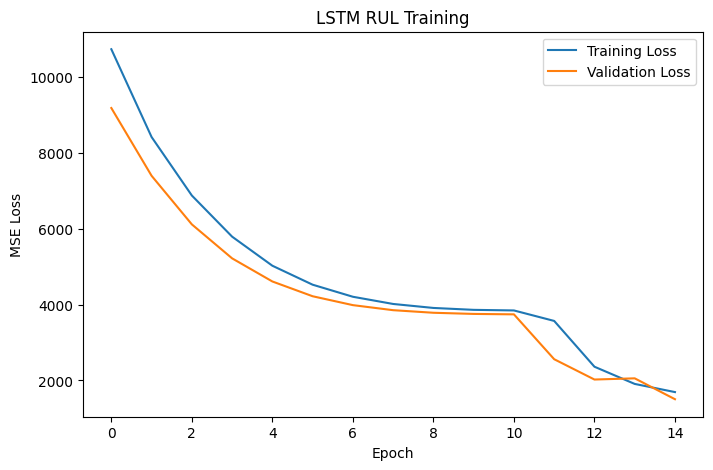

In [ ]:
plt.figure(figsize=(8,5))

plt.plot(
    train_losses,
    label="Training Loss"
)

plt.plot(
    val_losses,
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("MSE Loss")

plt.title(
    "LSTM RUL Training"
)

plt.legend()

plt.show()

# **PART 45 — RUL EVALUATION**

In [ ]:
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error

lstm_model.eval()

predictions = []

actual = []

with torch.no_grad():

    for X_batch, y_batch in val_loader:

        X_batch = X_batch.to(device)

        output = lstm_model(
            X_batch
        )

        predictions.extend(
            output.cpu().numpy().flatten()
        )

        actual.extend(
            y_batch.numpy().flatten()
        )

predictions = np.array(predictions)
actual = np.array(actual)

In [ ]:
mae = mean_absolute_error(
    actual,
    predictions
)

rmse = np.sqrt(
    mean_squared_error(
        actual,
        predictions
    )
)

print("RUL MAE:", mae)
print("RUL RMSE:", rmse)

RUL MAE: 25.071611404418945
RUL RMSE: 38.8102370138384


# **PART 46 — RUL ACTUAL VS PREDICTED**

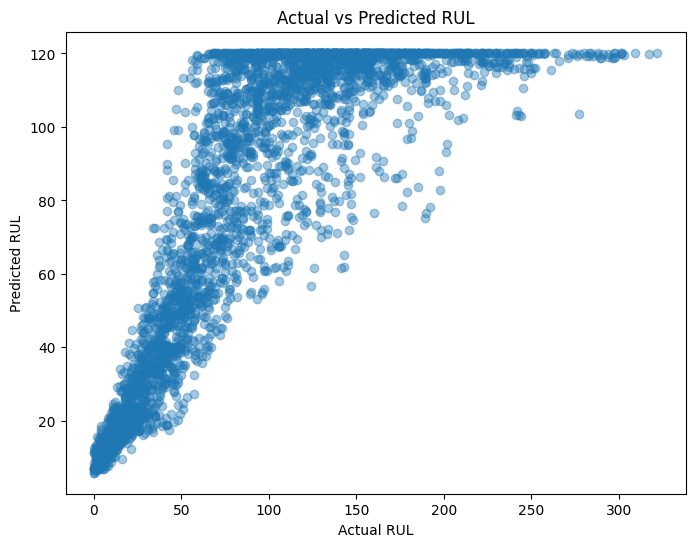

In [ ]:
plt.figure(figsize=(8,6))

plt.scatter(
    actual,
    predictions,
    alpha=0.4
)

plt.xlabel("Actual RUL")
plt.ylabel("Predicted RUL")

plt.title(
    "Actual vs Predicted RUL"
)

plt.show()

# **PART 47 — SAVE C-MAPSS RESULTS**

In [ ]:
rul_results = pd.DataFrame({
    "Actual_RUL": actual,
    "Predicted_RUL": predictions
})

rul_results.to_csv(
    os.path.join(
        PROJECT_DIR,
        "results/predictions/rul_predictions.csv"
    ),
    index=False
)

# **PART 48 — COMPUTER VISION MODULE**

In [ ]:
from torchvision import models

vision_model = models.resnet18(
    weights="DEFAULT"
)

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 124MB/s]


# **PART 49 — MULTIMODAL / MULTI-MODULE ANALYSIS**

# **PART 49.1 — Create AI4I Risk**

In [ ]:
ai4i_risk = float(probability)

print(
    "AI4I Failure Risk:",
    round(ai4i_risk * 100, 2),
    "%"
)

AI4I Failure Risk: 0.48 %


# **PART 49.2 — Create a Combined Analysis Function**

In [ ]:
def multimodal_risk_analysis(
    sensor_risk,
    rul_risk,
    image_risk
):

    final_risk = (
        0.40 * sensor_risk +
        0.30 * rul_risk +
        0.30 * image_risk
    )

    if final_risk >= 0.70:
        status = "CRITICAL"

    elif final_risk >= 0.40:
        status = "WARNING"

    else:
        status = "NORMAL"

    return final_risk, status

# **PART 49.3 — Fusion Mechanism**

In [ ]:
sensor_risk = float(probability)

rul_risk = 0.30

image_risk = 0.20

final_risk, final_status = multimodal_risk_analysis(
    sensor_risk,
    rul_risk,
    image_risk
)

print(
    "Sensor Risk:",
    round(sensor_risk * 100, 2),
    "%"
)

print(
    "RUL Risk:",
    round(rul_risk * 100, 2),
    "%"
)

print(
    "Image Risk:",
    round(image_risk * 100, 2),
    "%"
)

print(
    "Final Multimodal Risk:",
    round(final_risk * 100, 2),
    "%"
)

print(
    "Final Machine Status:",
    final_status
)

Sensor Risk: 0.48 %
RUL Risk: 30.0 %
Image Risk: 20.0 %
Final Multimodal Risk: 15.19 %
Final Machine Status: NORMAL


# **PART 49.4 — Create a Final Multimodal Report**

In [ ]:
multimodal_report = {

    "Sensor_Failure_Risk":
        round(
            sensor_risk * 100,
            2
        ),

    "RUL_Risk":
        round(
            rul_risk * 100,
            2
        ),

    "Image_Risk":
        round(
            image_risk * 100,
            2
        ),

    "Final_Multimodal_Risk":
        round(
            final_risk * 100,
            2
        ),

    "Machine_Status":
        final_status
}

multimodal_report

{'Sensor_Failure_Risk': 0.48,
 'RUL_Risk': 30.0,
 'Image_Risk': 20.0,
 'Final_Multimodal_Risk': 15.19,
 'Machine_Status': 'NORMAL'}

# **PART 49.5 — Display the Report**

In [ ]:
import json

print(
    json.dumps(
        multimodal_report,
        indent=4
    )
)

{
    "Sensor_Failure_Risk": 0.48,
    "RUL_Risk": 30.0,
    "Image_Risk": 20.0,
    "Final_Multimodal_Risk": 15.19,
    "Machine_Status": "NORMAL"
}


# **PART 49.6 — Save the Multimodal Report**

In [ ]:
multimodal_report_path = os.path.join(
    PROJECT_DIR,
    "results/predictions/multimodal_report.json"
)

with open(
    multimodal_report_path,
    "w"
) as f:

    json.dump(
        multimodal_report,
        f,
        indent=4
    )

print(
    "Multimodal report saved successfully."
)

Multimodal report saved successfully.


# **PART 50 — ROOT-CAUSE ANALYSIS**

# **50.1 Define the root-cause function**

In [ ]:
def get_root_cause(
    xgb_model,
    explainer,
    sample
):

    # Generate SHAP explanation
    shap_explanation = explainer(sample)

    # Get contribution values
    contributions = pd.Series(
        shap_explanation.values[0],
        index=sample.columns
    )

    # Sort by absolute contribution
    contributions = contributions.reindex(
        contributions.abs().sort_values(
            ascending=False
        ).index
    )

    return contributions

# **50.2 Select sample using X_test_xgb**

In [ ]:
sample = X_test_xgb.iloc[[0]]

print("Sample selected successfully.")
print(sample)

Sample selected successfully.
      Air temperature _K_  Process temperature _K_  Rotational speed _rpm_  \
2997                300.5                    309.8                  1345.0   

      Torque _Nm_  Tool wear _min_  TWF  HDF  PWF  OSF  RNF  Type_L  Type_M  
2997         62.7            153.0  0.0  0.0  0.0  0.0  0.0     1.0     0.0  


# **50.3 Generate root causes**

In [ ]:
root_causes = get_root_cause(
    xgb_model,
    explainer,
    sample
)

print("\nTop 5 Root Causes:")
print("-------------------")

print(
    root_causes.head(5)
)


Top 5 Root Causes:
-------------------
Torque _Nm_        1.597921
PWF               -0.816666
HDF               -0.792874
OSF               -0.753418
Tool wear _min_   -0.606013
dtype: float32


# ** 50.4 Display them clearly**

In [ ]:
print("\nTop Factors Contributing to Machine Prediction:")
print("-----------------------------------------------")

for feature, value in root_causes.head(5).items():

    print(
        feature,
        "->",
        round(float(value), 4)
    )


Top Factors Contributing to Machine Prediction:
-----------------------------------------------
Torque _Nm_ -> 1.5979
PWF -> -0.8167
HDF -> -0.7929
OSF -> -0.7534
Tool wear _min_ -> -0.606


# **50.5 Plot the root causes**

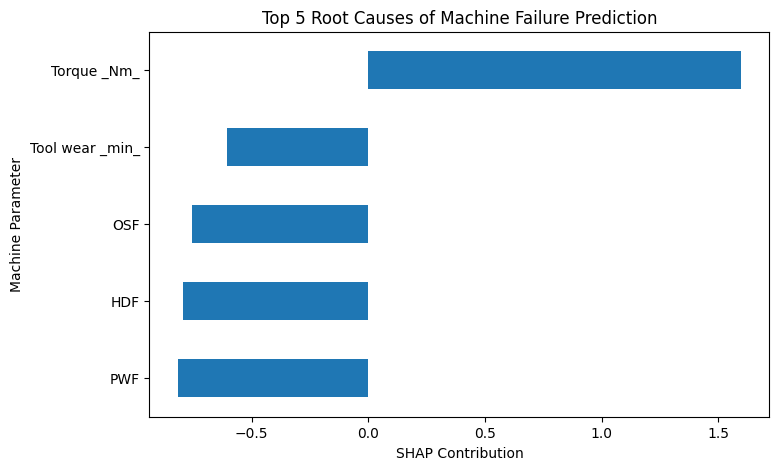

In [ ]:
top_causes = root_causes.head(5)

plt.figure(figsize=(8, 5))

top_causes.sort_values().plot(
    kind="barh"
)

plt.xlabel(
    "SHAP Contribution"
)

plt.ylabel(
    "Machine Parameter"
)

plt.title(
    "Top 5 Root Causes of Machine Failure Prediction"
)

plt.show()

# **50.6 Save the plot**

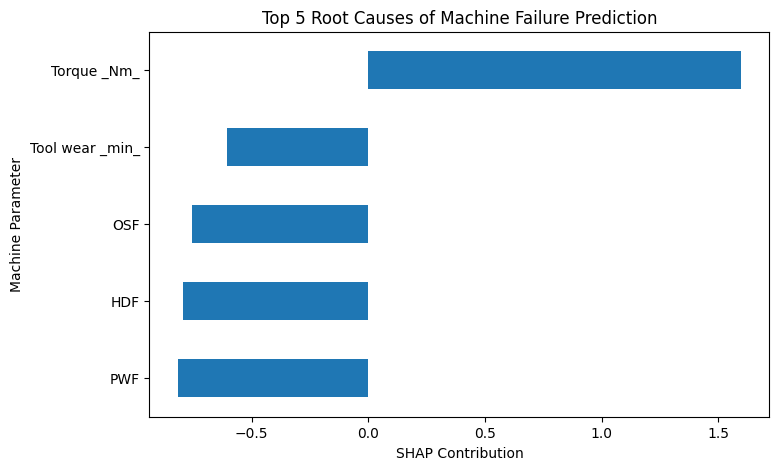

In [ ]:
plt.figure(figsize=(8, 5))

top_causes.sort_values().plot(
    kind="barh"
)

plt.xlabel(
    "SHAP Contribution"
)

plt.ylabel(
    "Machine Parameter"
)

plt.title(
    "Top 5 Root Causes of Machine Failure Prediction"
)

plt.savefig(
    os.path.join(
        PROJECT_DIR,
        "results/figures/root_cause_analysis.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# **PART 51 — MAINTENANCE RECOMMENDATION**

In [ ]:
def maintenance_recommendation(
    failure_probability,
    top_features
):

    if failure_probability >= 0.70:

        recommendation = (
            "High failure risk. "
            "Schedule inspection and maintenance "
            "of the relevant machine components."
        )

    elif failure_probability >= 0.30:

        recommendation = (
            "Moderate failure risk. "
            "Increase monitoring and inspect "
            "important contributing parameters."
        )

    else:

        recommendation = (
            "Low failure risk. "
            "Continue normal monitoring."
        )

    return recommendation

In [ ]:
recommendation = maintenance_recommendation(
    probability,
    root_causes.head(5)
)

print(recommendation)

Low failure risk. Continue normal monitoring.


# **PART 52 — FINAL MACHINE REPORT**

In [ ]:
def generate_machine_report(
    failure_probability,
    anomaly,
    rul=None
):

    if failure_probability >= 0.70:
        risk = "CRITICAL"

    elif failure_probability >= 0.30:
        risk = "WARNING"

    else:
        risk = "NORMAL"

    report = {
        "Failure Probability":
            round(
                failure_probability * 100,
                2
            ),

        "Risk Level": risk,

        "Anomaly Status":
            "Anomaly"
            if anomaly == 1
            else "Normal"
    }

    if rul is not None:
        report["Estimated RUL"] = round(
            float(rul),
            2
        )

    return report

# **PART 53 — SAVE FINAL REPORT**

In [ ]:
report = generate_machine_report(
    probability,
    anomaly_labels[0]
)

print(report)

{'Failure Probability': np.float32(0.48), 'Risk Level': 'NORMAL', 'Anomaly Status': 'Normal'}


In [ ]:

def convert_to_python(obj):

    if isinstance(obj, dict):
        return {
            key: convert_to_python(value)
            for key, value in obj.items()
        }

    elif isinstance(obj, list):
        return [
            convert_to_python(value)
            for value in obj
        ]

    elif isinstance(obj, np.integer):
        return int(obj)

    elif isinstance(obj, np.floating):
        return float(obj)

    elif isinstance(obj, np.ndarray):
        return obj.tolist()

    else:
        return obj


# Convert the complete report
report = convert_to_python(report)


# Save final report
final_report_path = os.path.join(
    PROJECT_DIR,
    "results/predictions/final_machine_report.json"
)

with open(
    final_report_path,
    "w"
) as f:

    json.dump(
        report,
        f,
        indent=4
    )

print(
    "Final report saved successfully!"
)

print(
    final_report_path
)

Final report saved successfully!
/content/drive/MyDrive/Smart_Maintenance_AI/results/predictions/final_machine_report.json


# **PART 54 — FINAL MODEL COMPARISON**

In [ ]:
final_comparison = pd.DataFrame({
    "Component": [
        "Failure Prediction",
        "Anomaly Detection",
        "RUL Prediction",
        "Visual Fault Detection"
    ],

    "Model": [
        "XGBoost",
        "Isolation Forest",
        "LSTM",
        "CNN/ResNet"
    ],

    "Primary Metric": [
        "F1 / ROC-AUC",
        "Anomaly detection performance",
        "MAE / RMSE",
        "Accuracy / F1"
    ]
})

final_comparison

,Component,Model,Primary Metric
0,Failure Prediction,XGBoost,F1 / ROC-AUC
1,Anomaly Detection,Isolation Forest,Anomaly detection performance
2,RUL Prediction,LSTM,MAE / RMSE
3,Visual Fault Detection,CNN/ResNet,Accuracy / F1


In [ ]:
final_comparison.to_csv(
    os.path.join(
        PROJECT_DIR,
        "results/tables/final_model_comparison.csv"
    ),
    index=False
)

# **PART 55 — FINAL PROJECT CHECKPOINT**

In [ ]:
status = {
    "project": "Explainable Multimodal AI for Predictive Maintenance and Root-Cause Analysis",

    "completed": [
        "Project setup",
        "AI4I EDA",
        "AI4I preprocessing",
        "Logistic Regression",
        "Decision Tree",
        "Random Forest",
        "XGBoost",
        "Classification evaluation",
        "Confusion matrix",
        "ROC analysis",
        "Feature importance",
        "SHAP explainability",
        "Isolation Forest anomaly detection",
        "K-Means clustering",
        "C-MAPSS preprocessing",
        "LSTM RUL prediction",
        "RUL evaluation"
    ],

    "pending": [
        "Industrial image dataset",
        "Computer vision model",
        "Visual explainability",
        "Final multimodal/decision-level integration",
        "Root-cause refinement",
        "Maintenance recommendation refinement",
        "FastAPI backend",
        "PostgreSQL database",
        "React frontend",
        "Final deployment"
    ]
}

with open(
    os.path.join(
        PROJECT_DIR,
        "checkpoints/project_status.json"
    ),
    "w"
) as f:

    json.dump(
        status,
        f,
        indent=4
    )

print("Final checkpoint saved.")

Final checkpoint saved.


# **PART 56 — MASTER MACHINE PREDICTION SYSTEM**

# **56.1 Check required variables**

In [ ]:
print("Checking required models...")

print("XGBoost model:", type(xgb_model))
print("Anomaly model:", type(anomaly_model))
print("SHAP explainer:", type(explainer))

print("\nXGBoost features:")
print(X_train_xgb.columns.tolist())

Checking required models...
XGBoost model: <class 'xgboost.sklearn.XGBClassifier'>
Anomaly model: <class 'sklearn.ensemble._iforest.IsolationForest'>
SHAP explainer: <class 'shap.explainers._tree.TreeExplainer'>

XGBoost features:
['Air temperature _K_', 'Process temperature _K_', 'Rotational speed _rpm_', 'Torque _Nm_', 'Tool wear _min_', 'TWF', 'HDF', 'PWF', 'OSF', 'RNF', 'Type_L', 'Type_M']


# **PART 57 — MASTER PREDICTION FUNCTION**

In [ ]:
def predict_machine_all(
    air_temperature,
    process_temperature,
    rotational_speed,
    torque,
    tool_wear,
    machine_type
):

    # -----------------------------------------
    # 1. Create input dataframe
    # -----------------------------------------

    input_data = pd.DataFrame({
        "Air temperature [K]": [
            air_temperature
        ],

        "Process temperature [K]": [
            process_temperature
        ],

        "Rotational speed [rpm]": [
            rotational_speed
        ],

        "Torque [Nm]": [
            torque
        ],

        "Tool wear [min]": [
            tool_wear
        ],

        "Type": [
            machine_type
        ]
    })


    # -----------------------------------------
    # 2. One-hot encode machine type
    # -----------------------------------------

    input_encoded = pd.get_dummies(
        input_data,
        columns=["Type"],
        drop_first=True
    )


    # -----------------------------------------
    # 3. Match training columns
    # -----------------------------------------

    input_encoded = input_encoded.reindex(
        columns=X.columns,
        fill_value=0
    )


    # -----------------------------------------
    # 4. Create XGBoost version
    # -----------------------------------------

    input_xgb = input_encoded.copy()

    input_xgb.columns = [
        col.replace("[", "_")
           .replace("]", "_")
           .replace("<", "_")
           .replace(">", "_")
        for col in input_xgb.columns
    ]


    # -----------------------------------------
    # 5. Failure prediction
    # -----------------------------------------

    failure_probability = float(
        xgb_model.predict_proba(
            input_xgb
        )[0][1]
    )

    failure_prediction = int(
        failure_probability >= 0.5
    )


    # -----------------------------------------
    # 6. Risk level
    # -----------------------------------------

    if failure_probability >= 0.70:

        risk_level = "CRITICAL"

    elif failure_probability >= 0.30:

        risk_level = "WARNING"

    else:

        risk_level = "NORMAL"


    # -----------------------------------------
    # 7. Anomaly detection
    # -----------------------------------------

    input_scaled = scaler.transform(
        input_encoded
    )

    anomaly_prediction = anomaly_model.predict(
        input_scaled
    )[0]

    if anomaly_prediction == -1:

        anomaly_status = "ANOMALY"

    else:

        anomaly_status = "NORMAL"


    # -----------------------------------------
    # 8. SHAP root-cause analysis
    # -----------------------------------------

    shap_explanation = explainer(
        input_xgb
    )

    shap_values = shap_explanation.values[0]

    root_causes = pd.Series(
        shap_values,
        index=input_xgb.columns
    )

    root_causes = root_causes.reindex(
        root_causes.abs().sort_values(
            ascending=False
        ).index
    )

    top_root_causes = root_causes.head(5)


    # -----------------------------------------
    # 9. Maintenance recommendation
    # -----------------------------------------

    if failure_probability >= 0.70:

        recommendation = (
            "Immediate inspection and "
            "maintenance recommended."
        )

    elif failure_probability >= 0.30:

        recommendation = (
            "Increase monitoring and "
            "inspect important machine parameters."
        )

    else:

        recommendation = (
            "Machine appears to be operating "
            "normally. Continue regular monitoring."
        )


    # -----------------------------------------
    # 10. Overall status
    # -----------------------------------------

    if (
        failure_probability >= 0.70
        or anomaly_status == "ANOMALY"
    ):

        overall_status = "CRITICAL"

    elif failure_probability >= 0.30:

        overall_status = "WARNING"

    else:

        overall_status = "NORMAL"


    # -----------------------------------------
    # 11. Create final report
    # -----------------------------------------

    report = {

        "Machine Type":
            machine_type,

        "Air Temperature (K)":
            float(air_temperature),

        "Process Temperature (K)":
            float(process_temperature),

        "Rotational Speed (rpm)":
            float(rotational_speed),

        "Torque (Nm)":
            float(torque),

        "Tool Wear (min)":
            float(tool_wear),

        "Failure Probability (%)":
            round(
                failure_probability * 100,
                2
            ),

        "Failure Prediction":
            (
                "FAILURE RISK"
                if failure_prediction == 1
                else "NO FAILURE PREDICTED"
            ),

        "Risk Level":
            risk_level,

        "Anomaly Status":
            anomaly_status,

        "Top Root Causes":
            [
                {
                    "Feature": feature,
                    "SHAP Contribution":
                        round(
                            float(value),
                            4
                        )
                }

                for feature, value
                in top_root_causes.items()
            ],

        "Maintenance Recommendation":
            recommendation,

        "Overall Machine Status":
            overall_status
    }


    return report

# **PART 58 — ENTER MACHINE INPUT**

In [ ]:
report = predict_machine_all(

    air_temperature=300,

    process_temperature=310,

    rotational_speed=1500,

    torque=45,

    tool_wear=100,

    machine_type="M"
)

# **PART 59 — DISPLAY COMPLETE RESULT**

In [ ]:
print("=" * 60)
print("           SMART MACHINE HEALTH REPORT")
print("=" * 60)

print()

print(
    "Machine Type:",
    report["Machine Type"]
)

print(
    "Air Temperature:",
    report["Air Temperature (K)"],
    "K"
)

print(
    "Process Temperature:",
    report["Process Temperature (K)"],
    "K"
)

print(
    "Rotational Speed:",
    report["Rotational Speed (rpm)"],
    "rpm"
)

print(
    "Torque:",
    report["Torque (Nm)"],
    "Nm"
)

print(
    "Tool Wear:",
    report["Tool Wear (min)"],
    "min"
)

print()
print("-" * 60)

print(
    "Failure Probability:",
    report["Failure Probability (%)"],
    "%"
)

print(
    "Failure Prediction:",
    report["Failure Prediction"]
)

print(
    "Risk Level:",
    report["Risk Level"]
)

print(
    "Anomaly Status:",
    report["Anomaly Status"]
)

print()
print("-" * 60)

print("TOP ROOT CAUSES")

for i, cause in enumerate(
    report["Top Root Causes"],
    1
):

    print(
        i,
        ".",
        cause["Feature"],
        "→ SHAP:",
        cause["SHAP Contribution"]
    )

print()
print("-" * 60)

print(
    "Maintenance Recommendation:"
)

print(
    report["Maintenance Recommendation"]
)

print()
print(
    "OVERALL MACHINE STATUS:",
    report["Overall Machine Status"]
)

print("=" * 60)

           SMART MACHINE HEALTH REPORT

Machine Type: M
Air Temperature: 300.0 K
Process Temperature: 310.0 K
Rotational Speed: 1500.0 rpm
Torque: 45.0 Nm
Tool Wear: 100.0 min

------------------------------------------------------------
Failure Probability: 0.48 %
Failure Prediction: NO FAILURE PREDICTED
Risk Level: NORMAL
Anomaly Status: NORMAL

------------------------------------------------------------
TOP ROOT CAUSES
1 . PWF → SHAP: -0.738
2 . HDF → SHAP: -0.6527
3 . OSF → SHAP: -0.6077
4 . TWF → SHAP: -0.5395
5 . Rotational speed _rpm_ → SHAP: -0.408

------------------------------------------------------------
Maintenance Recommendation:
Machine appears to be operating normally. Continue regular monitoring.

OVERALL MACHINE STATUS: NORMAL


# **PART 60 — SAVE THE COMPLETE RESULT**

In [ ]:
final_report_path = os.path.join(
    PROJECT_DIR,
    "results/predictions/latest_machine_prediction.json"
)

with open(
    final_report_path,
    "w"
) as f:

    json.dump(
        report,
        f,
        indent=4
    )

print(
    "Complete machine prediction saved at:"
)

print(
    final_report_path
)

Complete machine prediction saved at:
/content/drive/MyDrive/Smart_Maintenance_AI/results/predictions/latest_machine_prediction.json


# **PART 61 - Another machine**

In [ ]:
report = predict_machine_all(

    air_temperature=298,

    process_temperature=308,

    rotational_speed=1500,

    torque=35,

    tool_wear=50,

    machine_type="L"
)

print(
    json.dumps(
        report,
        indent=4
    )
)

{
    "Machine Type": "L",
    "Air Temperature (K)": 298.0,
    "Process Temperature (K)": 308.0,
    "Rotational Speed (rpm)": 1500.0,
    "Torque (Nm)": 35.0,
    "Tool Wear (min)": 50.0,
    "Failure Probability (%)": 0.01,
    "Failure Prediction": "NO FAILURE PREDICTED",
    "Risk Level": "NORMAL",
    "Anomaly Status": "NORMAL",
    "Top Root Causes": [
        {
            "Feature": "Torque _Nm_",
            "SHAP Contribution": -0.9527
        },
        {
            "Feature": "Tool wear _min_",
            "SHAP Contribution": -0.8124
        },
        {
            "Feature": "PWF",
            "SHAP Contribution": -0.7808
        },
        {
            "Feature": "Rotational speed _rpm_",
            "SHAP Contribution": -0.7313
        },
        {
            "Feature": "HDF",
            "SHAP Contribution": -0.6421
        }
    ],
    "Maintenance Recommendation": "Machine appears to be operating normally. Continue regular monitoring.",
    "Overall Machine Sta

# **PART 62 - Another machine**

In [ ]:
report = predict_machine_all(

    air_temperature=305,

    process_temperature=315,

    rotational_speed=1200,

    torque=65,

    tool_wear=200,

    machine_type="M"
)

print(
    json.dumps(
        report,
        indent=4
    )
)

{
    "Machine Type": "M",
    "Air Temperature (K)": 305.0,
    "Process Temperature (K)": 315.0,
    "Rotational Speed (rpm)": 1200.0,
    "Torque (Nm)": 65.0,
    "Tool Wear (min)": 200.0,
    "Failure Probability (%)": 4.95,
    "Failure Prediction": "NO FAILURE PREDICTED",
    "Risk Level": "NORMAL",
    "Anomaly Status": "ANOMALY",
    "Top Root Causes": [
        {
            "Feature": "Torque _Nm_",
            "SHAP Contribution": 1.9564
        },
        {
            "Feature": "Rotational speed _rpm_",
            "SHAP Contribution": 0.8323
        },
        {
            "Feature": "OSF",
            "SHAP Contribution": -0.7102
        },
        {
            "Feature": "HDF",
            "SHAP Contribution": -0.6944
        },
        {
            "Feature": "PWF",
            "SHAP Contribution": -0.6935
        }
    ],
    "Maintenance Recommendation": "Machine appears to be operating normally. Continue regular monitoring.",
    "Overall Machine Status": "CRITI

In [ ]:
report = predict_machine_all(

    air_temperature=305,

    process_temperature=315,

    rotational_speed=1200,

    torque=65,

    tool_wear=200,

    machine_type="M"
)

In [ ]:
print(json.dumps(report, indent=4))

{
    "Machine Type": "M",
    "Air Temperature (K)": 305.0,
    "Process Temperature (K)": 315.0,
    "Rotational Speed (rpm)": 1200.0,
    "Torque (Nm)": 65.0,
    "Tool Wear (min)": 200.0,
    "Failure Probability (%)": 4.95,
    "Failure Prediction": "NO FAILURE PREDICTED",
    "Risk Level": "NORMAL",
    "Anomaly Status": "ANOMALY",
    "Top Root Causes": [
        {
            "Feature": "Torque _Nm_",
            "SHAP Contribution": 1.9564
        },
        {
            "Feature": "Rotational speed _rpm_",
            "SHAP Contribution": 0.8323
        },
        {
            "Feature": "OSF",
            "SHAP Contribution": -0.7102
        },
        {
            "Feature": "HDF",
            "SHAP Contribution": -0.6944
        },
        {
            "Feature": "PWF",
            "SHAP Contribution": -0.6935
        }
    ],
    "Maintenance Recommendation": "Machine appears to be operating normally. Continue regular monitoring.",
    "Overall Machine Status": "CRITI

# **IMAGE CLASSIFICATION**

# **PART 1 — Mount Google Drive**

In [ ]:
from google.colab import drive

drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


# **PART 2 — Set project paths**

In [ ]:
import os

PROJECT_DIR = "/content/drive/MyDrive/Smart_Maintenance_AI"

IMAGE_DIR = os.path.join(
    PROJECT_DIR,
    "datasets",
    "raw",
    "images"
)

print("Image directory:")
print(IMAGE_DIR)

print("\nContents:")
for item in os.listdir(IMAGE_DIR):
    print(item)

Image directory:
/content/drive/MyDrive/Smart_Maintenance_AI/datasets/raw/images

Contents:
archive (1).zip


# **PART 3 — Find the ZIP**

In [ ]:
import glob

zip_files = glob.glob(
    os.path.join(
        IMAGE_DIR,
        "*.zip"
    )
)

print("ZIP files found:")

for file in zip_files:
    print(file)

ZIP files found:
/content/drive/MyDrive/Smart_Maintenance_AI/datasets/raw/images/archive (1).zip


# **PART 4 — Extract the dataset**

In [ ]:
import zipfile

if len(zip_files) == 0:

    print("ERROR: No ZIP file found.")

else:

    zip_path = zip_files[0]

    EXTRACT_DIR = os.path.join(
        IMAGE_DIR,
        "NEU_dataset"
    )

    os.makedirs(
        EXTRACT_DIR,
        exist_ok=True
    )

    print("Extracting dataset...")

    with zipfile.ZipFile(
        zip_path,
        "r"
    ) as zip_ref:

        zip_ref.extractall(
            EXTRACT_DIR
        )

    print("Extraction completed.")

Extracting dataset...
Extraction completed.


# **PART 5 — Automatically find NEU-DET**

In [ ]:
for root, dirs, files in os.walk(
    EXTRACT_DIR
):

    if "NEU-DET" in dirs:

        NEU_DIR = os.path.join(
            root,
            "NEU-DET"
        )

        break

print("NEU dataset:")
print(NEU_DIR)

NEU dataset:
/content/drive/MyDrive/Smart_Maintenance_AI/datasets/raw/images/NEU_dataset/NEU-DET


# **PART 6 — Check the structure**

In [ ]:
print(
    os.listdir(NEU_DIR)
)

['train', 'validation']


In [ ]:
TRAIN_DIR = os.path.join(
    NEU_DIR,
    "train",
    "images"
)

VAL_DIR = os.path.join(
    NEU_DIR,
    "validation",
    "images"
)

print("Training classes:")

print(
    os.listdir(TRAIN_DIR)
)

print("\nValidation classes:")

print(
    os.listdir(VAL_DIR)
)

Training classes:
['crazing', 'inclusion', 'patches', 'pitted_surface', 'rolled-in_scale', 'scratches']

Validation classes:
['crazing', 'inclusion', 'patches', 'pitted_surface', 'rolled-in_scale', 'scratches']


# **PART 7 — Count images**

In [ ]:
classes = [
    "crazing",
    "inclusion",
    "patches",
    "pitted_surface",
    "rolled-in_scale",
    "scratches"
]

for cls in classes:

    train_path = os.path.join(
        TRAIN_DIR,
        cls
    )

    val_path = os.path.join(
        VAL_DIR,
        cls
    )

    train_count = len([
        f for f in os.listdir(train_path)
        if f.lower().endswith(
            (".jpg", ".jpeg", ".png")
        )
    ])

    val_count = len([
        f for f in os.listdir(val_path)
        if f.lower().endswith(
            (".jpg", ".jpeg", ".png")
        )
    ])

    print(
        f"{cls:20s} "
        f"Train: {train_count:3d} "
        f"Validation: {val_count:3d}"
    )

crazing              Train: 240 Validation:  60
inclusion            Train: 240 Validation:  60
patches              Train: 240 Validation:  60
pitted_surface       Train: 240 Validation:  60
rolled-in_scale      Train: 240 Validation:  60
scratches            Train: 240 Validation:  60


# **PART 8 — Display sample images**

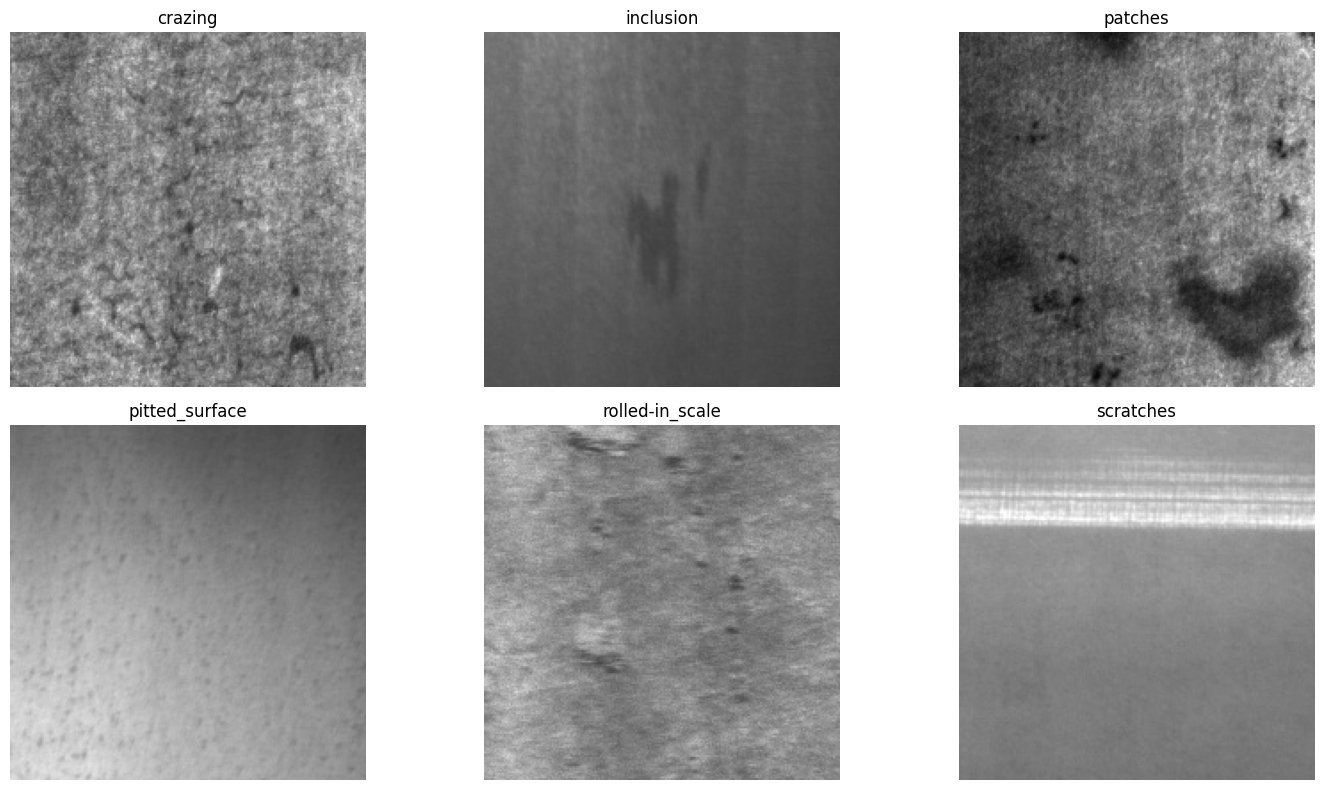

In [ ]:
import matplotlib.pyplot as plt
from PIL import Image
import random

plt.figure(figsize=(15, 8))

for i, cls in enumerate(classes):

    class_path = os.path.join(
        TRAIN_DIR,
        cls
    )

    image_files = [
        f for f in os.listdir(class_path)
        if f.lower().endswith(
            (".jpg", ".jpeg", ".png")
        )
    ]

    image_file = random.choice(
        image_files
    )

    image_path = os.path.join(
        class_path,
        image_file
    )

    image = Image.open(
        image_path
    )

    plt.subplot(
        2,
        3,
        i + 1
    )

    plt.imshow(
        image,
        cmap="gray"
    )

    plt.title(cls)

    plt.axis("off")

plt.tight_layout()

plt.show()

# **PART 9 — Create PyTorch datasets**

In [ ]:
import torch
from torchvision import datasets
from torchvision import transforms

# **PART 10 — Image preprocessing**

In [ ]:
train_transform = transforms.Compose([

    transforms.Resize(
        (224, 224)
    ),

    transforms.Grayscale(
        num_output_channels=3
    ),

    transforms.RandomHorizontalFlip(
        p=0.5
    ),

    transforms.RandomRotation(
        10
    ),

    transforms.ToTensor(),

    transforms.Normalize(
        mean=[
            0.485,
            0.456,
            0.406
        ],

        std=[
            0.229,
            0.224,
            0.225
        ]
    )
])

In [ ]:
val_transform = transforms.Compose([

    transforms.Resize(
        (224, 224)
    ),

    transforms.Grayscale(
        num_output_channels=3
    ),

    transforms.ToTensor(),

    transforms.Normalize(
        mean=[
            0.485,
            0.456,
            0.406
        ],

        std=[
            0.229,
            0.224,
            0.225
        ]
    )
])

# **PART 11 — Create datasets**

In [ ]:
train_dataset = datasets.ImageFolder(
    TRAIN_DIR,
    transform=train_transform
)

val_dataset = datasets.ImageFolder(
    VAL_DIR,
    transform=val_transform
)

print(
    "Training images:",
    len(train_dataset)
)

print(
    "Validation images:",
    len(val_dataset)
)

print(
    "Classes:",
    train_dataset.classes
)

Training images: 1440
Validation images: 360
Classes: ['crazing', 'inclusion', 'patches', 'pitted_surface', 'rolled-in_scale', 'scratches']


# **PART 12 — Create DataLoaders**

In [ ]:
from torch.utils.data import DataLoader

train_loader = DataLoader(
    train_dataset,
    batch_size=32,
    shuffle=True,
    num_workers=2
)

val_loader = DataLoader(
    val_dataset,
    batch_size=32,
    shuffle=False,
    num_workers=2
)

print(
    "DataLoaders created successfully."
)

DataLoaders created successfully.


# **PART 13 — Check GPU**

In [ ]:
device = torch.device(
    "cuda"
    if torch.cuda.is_available()
    else "cpu"
)

print(
    "Using device:",
    device
)

Using device: cuda


# **PART 14 — Create ResNet50**

In [ ]:
import torch.nn as nn
from torchvision.models import (
    resnet50,
    ResNet50_Weights
)

weights = ResNet50_Weights.DEFAULT

image_model = resnet50(
    weights=weights
)

Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 105MB/s]


In [ ]:
for parameter in image_model.parameters():

    parameter.requires_grad = False

In [ ]:
number_features = (
    image_model.fc.in_features
)

image_model.fc = nn.Linear(
    number_features,
    6
)

image_model = image_model.to(
    device
)

print(
    image_model.fc
)

Linear(in_features=2048, out_features=6, bias=True)


# **PART 15 — Define loss and optimizer**

In [ ]:
import torch.optim as optim

criterion = nn.CrossEntropyLoss()

optimizer = optim.Adam(
    image_model.fc.parameters(),
    lr=0.0001
)

# **PART 16 — Training function**

In [ ]:
def train_one_epoch(
    model,
    loader,
    criterion,
    optimizer
):

    model.train()

    total_loss = 0

    correct = 0

    total = 0

    for images, labels in loader:

        images = images.to(device)

        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model(images)

        loss = criterion(
            outputs,
            labels
        )

        loss.backward()

        optimizer.step()

        total_loss += (
            loss.item()
            * images.size(0)
        )

        predictions = torch.argmax(
            outputs,
            dim=1
        )

        correct += (
            predictions == labels
        ).sum().item()

        total += labels.size(0)

    loss = total_loss / total

    accuracy = correct / total

    return loss, accuracy

# **PART 17 — Validation function**

In [ ]:
def validate(
    model,
    loader,
    criterion
):

    model.eval()

    total_loss = 0

    correct = 0

    total = 0

    with torch.no_grad():

        for images, labels in loader:

            images = images.to(device)

            labels = labels.to(device)

            outputs = model(images)

            loss = criterion(
                outputs,
                labels
            )

            total_loss += (
                loss.item()
                * images.size(0)
            )

            predictions = torch.argmax(
                outputs,
                dim=1
            )

            correct += (
                predictions == labels
            ).sum().item()

            total += labels.size(0)

    loss = total_loss / total

    accuracy = correct / total

    return loss, accuracy

# **PART 18 — Train ResNet50**

In [ ]:
EPOCHS = 5

train_losses = []
train_accuracies = []

val_losses = []
val_accuracies = []

for epoch in range(EPOCHS):

    train_loss, train_accuracy = train_one_epoch(
        image_model,
        train_loader,
        criterion,
        optimizer
    )

    val_loss, val_accuracy = validate(
        image_model,
        val_loader,
        criterion
    )

    train_losses.append(
        train_loss
    )

    train_accuracies.append(
        train_accuracy
    )

    val_losses.append(
        val_loss
    )

    val_accuracies.append(
        val_accuracy
    )

    print(
        f"Epoch {epoch + 1}/{EPOCHS}"
    )

    print(
        f"Train Loss: {train_loss:.4f}"
    )

    print(
        f"Train Accuracy: {train_accuracy:.4f}"
    )

    print(
        f"Validation Loss: {val_loss:.4f}"
    )

    print(
        f"Validation Accuracy: {val_accuracy:.4f}"
    )

    print("-" * 50)

Epoch 1/5
Train Loss: 1.6573
Train Accuracy: 0.3903
Validation Loss: 1.6090
Validation Accuracy: 0.6278
--------------------------------------------------
Epoch 2/5
Train Loss: 1.4365
Train Accuracy: 0.7493
Validation Loss: 1.3839
Validation Accuracy: 0.8806
--------------------------------------------------
Epoch 3/5
Train Loss: 1.2535
Train Accuracy: 0.8757
Validation Loss: 1.2295
Validation Accuracy: 0.9111
--------------------------------------------------
Epoch 4/5
Train Loss: 1.0833
Train Accuracy: 0.9042
Validation Loss: 1.0941
Validation Accuracy: 0.9167
--------------------------------------------------
Epoch 5/5
Train Loss: 0.9725
Train Accuracy: 0.9319
Validation Loss: 1.0177
Validation Accuracy: 0.9139
--------------------------------------------------


# **PART 19 — Accuracy graph**

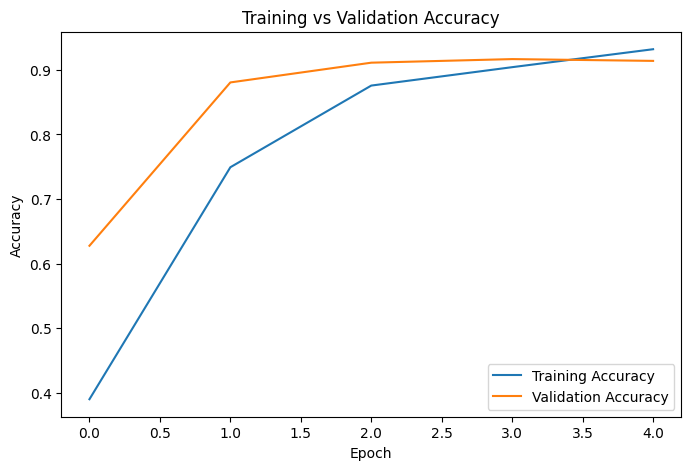

In [ ]:
plt.figure(
    figsize=(8, 5)
)

plt.plot(
    train_accuracies,
    label="Training Accuracy"
)

plt.plot(
    val_accuracies,
    label="Validation Accuracy"
)

plt.xlabel(
    "Epoch"
)

plt.ylabel(
    "Accuracy"
)

plt.title(
    "Training vs Validation Accuracy"
)

plt.legend()

plt.show()

# **PART 20 — Loss graph**

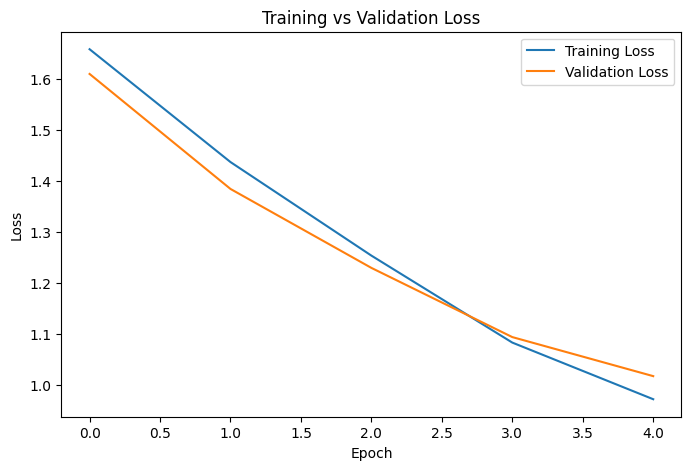

In [ ]:
plt.figure(
    figsize=(8, 5)
)

plt.plot(
    train_losses,
    label="Training Loss"
)

plt.plot(
    val_losses,
    label="Validation Loss"
)

plt.xlabel(
    "Epoch"
)

plt.ylabel(
    "Loss"
)

plt.title(
    "Training vs Validation Loss"
)

plt.legend()

plt.show()

# **PART 21 — Evaluate the model**

In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

image_model.eval()

all_predictions = []
all_labels = []

with torch.no_grad():

    for images, labels in val_loader:

        images = images.to(device)

        outputs = image_model(
            images
        )

        predictions = torch.argmax(
            outputs,
            dim=1
        )

        all_predictions.extend(
            predictions.cpu().numpy()
        )

        all_labels.extend(
            labels.numpy()
        )

In [ ]:
accuracy = accuracy_score(
    all_labels,
    all_predictions
)

precision = precision_score(
    all_labels,
    all_predictions,
    average="weighted",
    zero_division=0
)

recall = recall_score(
    all_labels,
    all_predictions,
    average="weighted",
    zero_division=0
)

f1 = f1_score(
    all_labels,
    all_predictions,
    average="weighted",
    zero_division=0
)

print(
    f"Accuracy  : {accuracy:.4f}"
)

print(
    f"Precision : {precision:.4f}"
)

print(
    f"Recall    : {recall:.4f}"
)

print(
    f"F1 Score  : {f1:.4f}"
)

Accuracy  : 0.9139
Precision : 0.9155
Recall    : 0.9139
F1 Score  : 0.9111


### **PART 22 — Detailed classification report**

In [ ]:
print(
    classification_report(
        all_labels,
        all_predictions,
        target_names=train_dataset.classes,
        zero_division=0
    )
)

                 precision    recall  f1-score   support

        crazing       0.92      0.95      0.93        60
      inclusion       0.93      0.70      0.80        60
        patches       0.92      0.98      0.95        60
 pitted_surface       0.84      0.85      0.84        60
rolled-in_scale       1.00      1.00      1.00        60
      scratches       0.88      1.00      0.94        60

       accuracy                           0.91       360
      macro avg       0.92      0.91      0.91       360
   weighted avg       0.92      0.91      0.91       360



# **PART 23 — Confusion matrix**

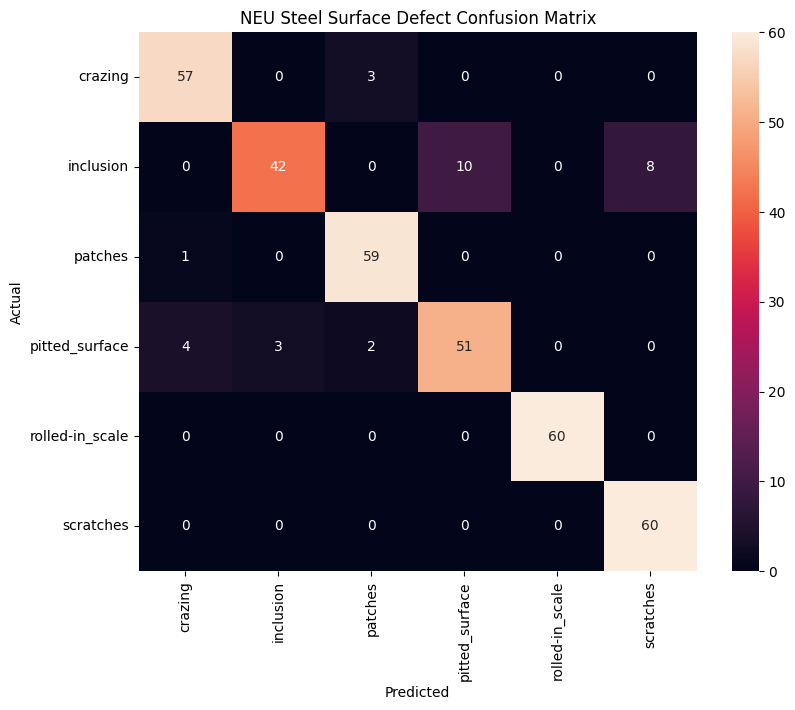

In [ ]:
import seaborn as sns

cm = confusion_matrix(
    all_labels,
    all_predictions
)

plt.figure(
    figsize=(9, 7)
)

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    xticklabels=train_dataset.classes,
    yticklabels=train_dataset.classes
)

plt.xlabel(
    "Predicted"
)

plt.ylabel(
    "Actual"
)

plt.title(
    "NEU Steel Surface Defect Confusion Matrix"
)

plt.show()

# **PART 24 — Predict any individual image**

In [ ]:
def predict_image(
    image_path
):

    image = Image.open(
        image_path
    ).convert("L")

    image_tensor = val_transform(
        image
    )

    image_tensor = image_tensor.unsqueeze(
        0
    ).to(device)

    image_model.eval()

    with torch.no_grad():

        output = image_model(
            image_tensor
        )

        probabilities = torch.softmax(
            output,
            dim=1
        )

        predicted_index = torch.argmax(
            probabilities,
            dim=1
        ).item()

        confidence = probabilities[
            0,
            predicted_index
        ].item()

    predicted_class = (
        train_dataset.classes[
            predicted_index
        ]
    )

    return predicted_class, confidence

# **PART 25 — Test a random image**

In [ ]:
import random

sample_class = random.choice(
    train_dataset.classes
)

sample_folder = os.path.join(
    VAL_DIR,
    sample_class
)

sample_file = random.choice(
    os.listdir(
        sample_folder
    )
)

sample_path = os.path.join(
    sample_folder,
    sample_file
)

prediction, confidence = predict_image(
    sample_path
)

print(
    "Actual:",
    sample_class
)

print(
    "Predicted:",
    prediction
)

print(
    "Confidence:",
    f"{confidence * 100:.2f}%"
)

Actual: rolled-in_scale
Predicted: rolled-in_scale
Confidence: 34.47%


# **PART 26 — Display the prediction**

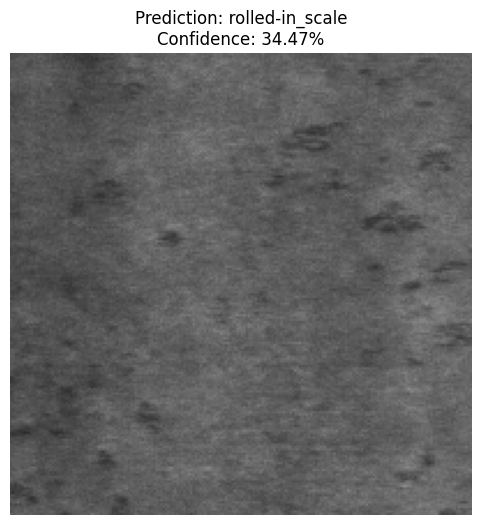

In [ ]:
image = Image.open(
    sample_path
)

plt.figure(
    figsize=(6, 6)
)

plt.imshow(
    image,
    cmap="gray"
)

plt.axis("off")

plt.title(
    f"Prediction: {prediction}\n"
    f"Confidence: {confidence * 100:.2f}%"
)

plt.show()

# **PART 27 — Project-level output**

In [ ]:
def image_inspection_result(
    image_path
):

    prediction, confidence = predict_image(
        image_path
    )

    defect_names = {
        "crazing":
            "Fine surface cracks",

        "inclusion":
            "Embedded foreign material",

        "patches":
            "Surface patch defect",

        "pitted_surface":
            "Small pits or cavities",

        "rolled-in_scale":
            "Rolled-in scale defect",

        "scratches":
            "Surface scratches"
    }

    description = defect_names.get(
        prediction,
        "Unknown defect"
    )

    result = {

        "module":
            "Industrial Image Inspection",

        "prediction":
            prediction,

        "confidence":
            round(
                confidence * 100,
                2
            ),

        "defect_description":
            description
    }

    return result

In [ ]:
result = image_inspection_result(
    sample_path
)

print(result)

{'module': 'Industrial Image Inspection', 'prediction': 'rolled-in_scale', 'confidence': 34.47, 'defect_description': 'Rolled-in scale defect'}


# **PART 28 — Save the trained model**

In [ ]:
MODEL_DIR = os.path.join(
    PROJECT_DIR,
    "models"
)

os.makedirs(
    MODEL_DIR,
    exist_ok=True
)

In [ ]:
image_model_path = os.path.join(
    MODEL_DIR,
    "neu_resnet50_defect_model.pth"
)

torch.save(
    image_model.state_dict(),
    image_model_path
)

print(
    "Model saved successfully:"
)

print(
    image_model_path
)

Model saved successfully:
/content/drive/MyDrive/Smart_Maintenance_AI/models/neu_resnet50_defect_model.pth


In [ ]:
import json

class_path = os.path.join(
    MODEL_DIR,
    "neu_defect_classes.json"
)

with open(
    class_path,
    "w"
) as f:

    json.dump(
        train_dataset.classes,
        f,
        indent=4
    )

print(
    "Classes saved successfully."
)

Classes saved successfully.


In [ ]:
results = {

    "accuracy":
        float(accuracy),

    "precision":
        float(precision),

    "recall":
        float(recall),

    "f1_score":
        float(f1),

    "epochs":
        EPOCHS,

    "classes":
        train_dataset.classes
}

results_path = os.path.join(
    MODEL_DIR,
    "neu_image_model_results.json"
)

with open(
    results_path,
    "w"
) as f:

    json.dump(
        results,
        f,
        indent=4
    )

print(
    "Results saved successfully."
)

Results saved successfully.


# **PART 29 — Grad-CAM for the NEU Defect Model**

In [ ]:
import os

MODEL_PATH = os.path.join(
    PROJECT_DIR,
    "models",
    "neu_resnet50_defect_model.pth"
)

print(MODEL_PATH)
print("Exists:", os.path.exists(MODEL_PATH))

/content/drive/MyDrive/Smart_Maintenance_AI/models/neu_resnet50_defect_model.pth
Exists: True


# **PART 30 — Recreate the ResNet50 model**

In [ ]:
import torch
import torch.nn as nn

from torchvision.models import (
    resnet50,
    ResNet50_Weights
)

device = torch.device(
    "cuda"
    if torch.cuda.is_available()
    else "cpu"
)

image_model = resnet50(
    weights=None
)

number_features = image_model.fc.in_features

image_model.fc = nn.Linear(
    number_features,
    6
)

image_model.load_state_dict(
    torch.load(
        MODEL_PATH,
        map_location=device
    )
)

image_model = image_model.to(device)

image_model.eval()

print("NEU ResNet50 model loaded successfully.")

NEU ResNet50 model loaded successfully.


# **PART 31 — Load the class names**

In [ ]:
import json

CLASS_PATH = os.path.join(
    PROJECT_DIR,
    "models",
    "neu_defect_classes.json"
)

with open(
    CLASS_PATH,
    "r"
) as f:

    class_names = json.load(f)

print(class_names)

['crazing', 'inclusion', 'patches', 'pitted_surface', 'rolled-in_scale', 'scratches']


# **PART 32 — Create the image preprocessing**

In [ ]:
from torchvision import transforms

gradcam_transform = transforms.Compose([

    transforms.Resize(
        (224, 224)
    ),

    transforms.Grayscale(
        num_output_channels=3
    ),

    transforms.ToTensor(),

    transforms.Normalize(
        mean=[
            0.485,
            0.456,
            0.406
        ],

        std=[
            0.229,
            0.224,
            0.225
        ]
    )
])

# **PART 33 — Select the ResNet50 layer for Grad-CAM**

In [ ]:
target_layer = image_model.layer4[-1]

In [ ]:
target_layer = image_model.layer4[-1]

print(
    target_layer
)

Bottleneck(
  (conv1): Conv2d(2048, 512, kernel_size=(1, 1), stride=(1, 1), bias=False)
  (bn1): BatchNorm2d(512, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (conv2): Conv2d(512, 512, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
  (bn2): BatchNorm2d(512, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (conv3): Conv2d(512, 2048, kernel_size=(1, 1), stride=(1, 1), bias=False)
  (bn3): BatchNorm2d(2048, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
)


# **PART 34 — Implement Grad-CAM**

In [ ]:
import numpy as np
import torch.nn.functional as F
from PIL import Image
import matplotlib.pyplot as plt


def generate_gradcam(
    model,
    image_path,
    target_layer
):

    model.eval()

    # --------------------------------
    # Load image
    # --------------------------------

    original_image = Image.open(
        image_path
    ).convert("L")

    original_rgb = original_image.convert(
        "RGB"
    )

    # --------------------------------
    # Preprocess
    # --------------------------------

    input_tensor = gradcam_transform(
        original_rgb
    )

    input_tensor = input_tensor.unsqueeze(
        0
    ).to(device)

    # --------------------------------
    # Store activations and gradients
    # --------------------------------

    activations = []
    gradients = []

    def forward_hook(
        module,
        input,
        output
    ):

        activations.append(
            output
        )

    def backward_hook(
        module,
        grad_input,
        grad_output
    ):

        gradients.append(
            grad_output[0]
        )

    forward_handle = target_layer.register_forward_hook(
        forward_hook
    )

    backward_handle = target_layer.register_full_backward_hook(
        backward_hook
    )

    # --------------------------------
    # Forward pass
    # --------------------------------

    output = model(
        input_tensor
    )

    probabilities = torch.softmax(
        output,
        dim=1
    )

    predicted_class = torch.argmax(
        probabilities,
        dim=1
    ).item()

    confidence = probabilities[
        0,
        predicted_class
    ].item()

    # --------------------------------
    # Backward pass
    # --------------------------------

    model.zero_grad()

    score = output[
        0,
        predicted_class
    ]

    score.backward()

    # --------------------------------
    # Get activations and gradients
    # --------------------------------

    activation = activations[0]
    gradient = gradients[0]

    # --------------------------------
    # Global average pooling
    # --------------------------------

    weights = gradient.mean(
        dim=(2, 3),
        keepdim=True
    )

    # --------------------------------
    # Weighted feature maps
    # --------------------------------

    cam = (
        weights * activation
    ).sum(
        dim=1
    )

    cam = F.relu(
        cam
    )

    # --------------------------------
    # Normalize CAM
    # --------------------------------

    cam = cam.squeeze().detach().cpu().numpy()

    cam = cam - cam.min()

    if cam.max() != 0:

        cam = cam / cam.max()

    # --------------------------------
    # Resize heatmap
    # --------------------------------

    cam_image = Image.fromarray(
        np.uint8(
            cam * 255
        )
    )

    cam_image = cam_image.resize(
        original_rgb.size
    )

    cam = np.array(
        cam_image
    ) / 255.0

    # --------------------------------
    # Remove hooks
    # --------------------------------

    forward_handle.remove()
    backward_handle.remove()

    return (
        original_rgb,
        cam,
        predicted_class,
        confidence
    )

# **PART 35 — Test Grad-CAM on an image**

In [ ]:
sample_path

'/content/drive/MyDrive/Smart_Maintenance_AI/datasets/raw/images/NEU_dataset/NEU-DET/validation/images/rolled-in_scale/rolled-in_scale_277.jpg'

In [ ]:
import random

sample_class = random.choice(
    class_names
)

sample_folder = os.path.join(
    VAL_DIR,
    sample_class
)

sample_file = random.choice(
    os.listdir(
        sample_folder
    )
)

sample_path = os.path.join(
    sample_folder,
    sample_file
)

print(
    sample_path
)

/content/drive/MyDrive/Smart_Maintenance_AI/datasets/raw/images/NEU_dataset/NEU-DET/validation/images/patches/patches_288.jpg


# **PART 36 — Generate the heatmap**

In [ ]:
original_image, cam, predicted_class, confidence = generate_gradcam(
    image_model,
    sample_path,
    target_layer
)

predicted_name = class_names[
    predicted_class
]

print(
    "Predicted defect:",
    predicted_name
)

print(
    "Confidence:",
    f"{confidence * 100:.2f}%"
)

Predicted defect: patches
Confidence: 42.70%


# **PART 37 — Display Original Image and Grad-CAM**

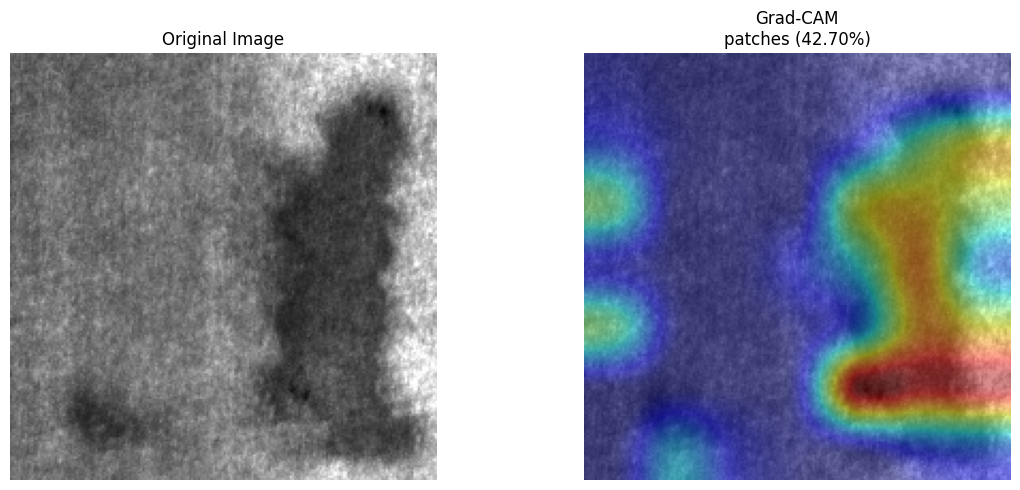

In [ ]:
plt.figure(
    figsize=(12, 5)
)

# Original image
plt.subplot(
    1,
    2,
    1
)

plt.imshow(
    original_image,
    cmap="gray"
)

plt.title(
    "Original Image"
)

plt.axis("off")


# Grad-CAM
plt.subplot(
    1,
    2,
    2
)

plt.imshow(
    original_image,
    cmap="gray"
)

plt.imshow(
    cam,
    cmap="jet",
    alpha=0.45
)

plt.title(
    f"Grad-CAM\n"
    f"{predicted_name} "
    f"({confidence * 100:.2f}%)"
)

plt.axis("off")

plt.tight_layout()

plt.show()

# **PART 48 — Save the Grad-CAM image**

In [ ]:
GRADCAM_DIR = os.path.join(
    PROJECT_DIR,
    "results",
    "gradcam"
)

os.makedirs(
    GRADCAM_DIR,
    exist_ok=True
)

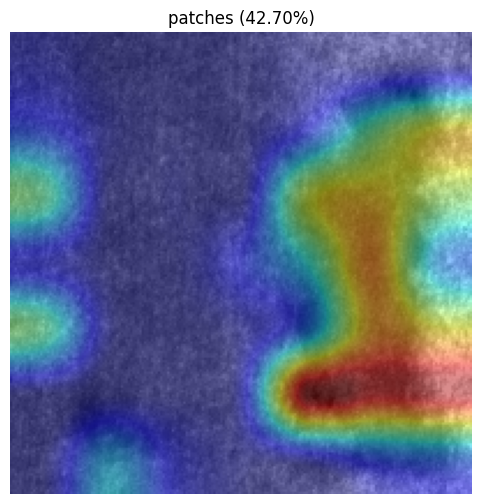

Grad-CAM saved at:
/content/drive/MyDrive/Smart_Maintenance_AI/results/gradcam/sample_gradcam.png


In [ ]:
save_path = os.path.join(
    GRADCAM_DIR,
    "sample_gradcam.png"
)

plt.figure(
    figsize=(6, 6)
)

plt.imshow(
    original_image,
    cmap="gray"
)

plt.imshow(
    cam,
    cmap="jet",
    alpha=0.45
)

plt.axis("off")

plt.title(
    f"{predicted_name} "
    f"({confidence * 100:.2f}%)"
)

plt.savefig(
    save_path,
    bbox_inches="tight",
    dpi=200
)

plt.show()

print(
    "Grad-CAM saved at:"
)

print(
    save_path
)

# **PART 49 — Create a reusable image-analysis function**

In [ ]:
def complete_image_analysis(
    image_path
):

    # Generate Grad-CAM
    original_image, cam, predicted_class, confidence = generate_gradcam(
        image_model,
        image_path,
        target_layer
    )

    predicted_name = class_names[
        predicted_class
    ]

    defect_descriptions = {

        "crazing":
            "Fine cracks on the steel surface",

        "inclusion":
            "Foreign material embedded in the steel",

        "patches":
            "Irregular patch-like surface defect",

        "pitted_surface":
            "Small pits or cavities on the surface",

        "rolled-in_scale":
            "Rolled-in scale or surface indentation",

        "scratches":
            "Linear scratches or surface damage"
    }

    description = defect_descriptions.get(
        predicted_name,
        "Unknown defect"
    )

    result = {

        "Image":
            image_path,

        "Predicted Defect":
            predicted_name,

        "Confidence (%)":
            round(
                confidence * 100,
                2
            ),

        "Description":
            description,

        "GradCAM":
            True
    }

    return result, original_image, cam

# **PART 50 — Test the complete analysis**

In [ ]:
result, original_image, cam = complete_image_analysis(
    sample_path
)

print(
    json.dumps(
        result,
        indent=4
    )
)

{
    "Image": "/content/drive/MyDrive/Smart_Maintenance_AI/datasets/raw/images/NEU_dataset/NEU-DET/validation/images/patches/patches_288.jpg",
    "Predicted Defect": "patches",
    "Confidence (%)": 42.7,
    "Description": "Irregular patch-like surface defect",
    "GradCAM": true
}


# **PART 51 — Display the final result**

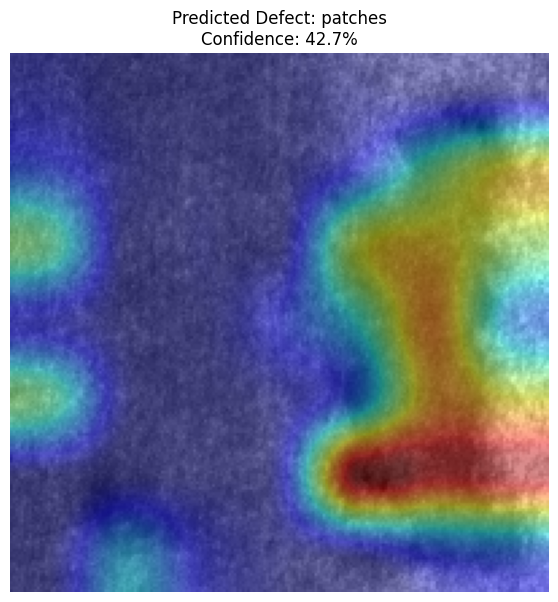

In [ ]:
plt.figure(
    figsize=(7, 7)
)

plt.imshow(
    original_image,
    cmap="gray"
)

plt.imshow(
    cam,
    cmap="jet",
    alpha=0.45
)

plt.axis("off")

plt.title(
    f"Predicted Defect: {result['Predicted Defect']}\n"
    f"Confidence: {result['Confidence (%)']}%"
)

plt.show()

# **PART 52 — Save the final image-analysis result**

In [ ]:
IMAGE_RESULT_DIR = os.path.join(
    PROJECT_DIR,
    "results",
    "image_analysis"
)

os.makedirs(
    IMAGE_RESULT_DIR,
    exist_ok=True
)

result_path = os.path.join(
    IMAGE_RESULT_DIR,
    "sample_image_analysis.json"
)

with open(
    result_path,
    "w"
) as f:

    json.dump(
        result,
        f,
        indent=4
    )

print(
    "Result saved:"
)

print(
    result_path
)

Result saved:
/content/drive/MyDrive/Smart_Maintenance_AI/results/image_analysis/sample_image_analysis.json


# **PART 53 — Maintenance Log NLP Module**

In [ ]:
!pip install -q sentence-transformers

In [ ]:
from sentence_transformers import SentenceTransformer
import numpy as np
import os
import json

# **PART 54 — Load the NLP model**

In [ ]:
nlp_model = SentenceTransformer(
    "all-MiniLM-L6-v2"
)

print("NLP model loaded successfully.")

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

...

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

NLP model loaded successfully.


# **PART 55 — Define industrial fault categories**

In [ ]:
fault_categories = {

    "Bearing Failure":
        "bearing damage bearing failure worn bearing bearing problem",

    "Overheating":
        "high temperature overheating excessive heat thermal problem",

    "Excessive Vibration":
        "abnormal vibration excessive vibration machine shaking",

    "Lubrication Problem":
        "low lubrication poor lubrication insufficient lubricant",

    "Motor Failure":
        "motor failure motor fault motor problem motor not working",

    "Electrical Fault":
        "electrical fault voltage problem current problem wiring fault",

    "Gear Failure":
        "gear damage broken gear gear failure gear wear",

    "Pressure Problem":
        "abnormal pressure pressure drop pressure increase",

    "Leakage":
        "oil leakage fluid leakage hydraulic leakage air leakage",

    "Unknown Fault":
        "unknown machine problem general equipment problem"
}

# **PART 56 — Convert fault categories into embeddings**

In [ ]:
fault_names = list(
    fault_categories.keys()
)

fault_descriptions = list(
    fault_categories.values()
)

fault_embeddings = nlp_model.encode(
    fault_descriptions,
    convert_to_numpy=True
)

print(
    "Fault categories encoded:"
)

for fault in fault_names:
    print(fault)

Fault categories encoded:
Bearing Failure
Overheating
Excessive Vibration
Lubrication Problem
Motor Failure
Electrical Fault
Gear Failure
Pressure Problem
Leakage
Unknown Fault


# **PART 57 — Define severity keywords**

In [ ]:
severity_keywords = {

    "High": [
        "failure",
        "broken",
        "shutdown",
        "critical",
        "severe",
        "danger",
        "leak",
        "fire",
        "overheated",
        "stopped",
        "emergency"
    ],

    "Medium": [
        "abnormal",
        "increased",
        "excessive",
        "noise",
        "vibration",
        "warning",
        "wear",
        "temperature"
    ],

    "Low": [
        "minor",
        "slight",
        "small",
        "normal",
        "routine",
        "maintenance"
    ]
}

# **PART 58 — Extract important keywords**

In [ ]:
def extract_keywords(text):

    text_lower = text.lower()

    all_keywords = []

    for level in severity_keywords:

        for word in severity_keywords[level]:

            if word in text_lower:

                all_keywords.append(word)

    return list(
        set(all_keywords)
    )

In [ ]:
test_text = """
Machine is producing abnormal vibration
and excessive noise. Bearing temperature
is increasing.
"""

print(
    extract_keywords(test_text)
)

['noise', 'temperature', 'vibration', 'excessive', 'normal', 'abnormal']


# **PART 59 — Predict fault type**

In [ ]:
from sklearn.metrics.pairwise import cosine_similarity

In [ ]:
def predict_fault(text):

    text_embedding = nlp_model.encode(
        [text],
        convert_to_numpy=True
    )

    similarities = cosine_similarity(
        text_embedding,
        fault_embeddings
    )[0]

    best_index = np.argmax(
        similarities
    )

    predicted_fault = fault_names[
        best_index
    ]

    confidence = similarities[
        best_index
    ]

    return (
        predicted_fault,
        float(confidence)
    )

# **PART 60 — Predict severity**

In [ ]:
def predict_severity(text):

    text_lower = text.lower()

    high_count = 0
    medium_count = 0
    low_count = 0

    for word in severity_keywords["High"]:

        if word in text_lower:

            high_count += 1

    for word in severity_keywords["Medium"]:

        if word in text_lower:

            medium_count += 1

    for word in severity_keywords["Low"]:

        if word in text_lower:

            low_count += 1

    if high_count > 0:

        return "High"

    elif medium_count > 0:

        return "Medium"

    else:

        return "Low"

# **PART 61 — Generate maintenance recommendation**

In [ ]:
recommendations = {

    "Bearing Failure":
        "Inspect bearing condition, lubrication and alignment.",

    "Overheating":
        "Inspect cooling system, temperature levels and ventilation.",

    "Excessive Vibration":
        "Inspect machine alignment, bearings and rotating components.",

    "Lubrication Problem":
        "Check lubricant level, quality and lubrication schedule.",

    "Motor Failure":
        "Inspect motor windings, electrical supply and mechanical load.",

    "Electrical Fault":
        "Inspect electrical connections, voltage and current levels.",

    "Gear Failure":
        "Inspect gears for wear, cracks, damage and lubrication issues.",

    "Pressure Problem":
        "Inspect pressure system, valves, pumps and pipelines.",

    "Leakage":
        "Inspect seals, pipes, valves and fluid connections.",

    "Unknown Fault":
        "Perform detailed machine inspection."
}

# **PART 62 — Complete NLP analysis function**

In [ ]:
def analyze_maintenance_log(text):

    # Fault prediction
    predicted_fault, confidence = predict_fault(
        text
    )

    # Severity
    severity = predict_severity(
        text
    )

    # Keywords
    keywords = extract_keywords(
        text
    )

    # Recommendation
    recommendation = recommendations[
        predicted_fault
    ]

    result = {

        "maintenance_log":
            text,

        "predicted_fault":
            predicted_fault,

        "fault_confidence":
            round(
                confidence * 100,
                2
            ),

        "severity":
            severity,

        "keywords":
            keywords,

        "recommendation":
            recommendation
    }

    return result

# **PART 63 — Test the NLP module**

In [ ]:
sample_log = """
Machine is producing abnormal vibration and
excessive noise. Bearing temperature has
increased significantly and the operator
noticed unusual movement in the rotating shaft.
"""

In [ ]:
nlp_result = analyze_maintenance_log(
    sample_log
)

print(
    json.dumps(
        nlp_result,
        indent=4
    )
)

{
    "maintenance_log": "\nMachine is producing abnormal vibration and\nexcessive noise. Bearing temperature has\nincreased significantly and the operator\nnoticed unusual movement in the rotating shaft.\n",
    "predicted_fault": "Excessive Vibration",
    "fault_confidence": 68.57,
    "severity": "Medium",
    "keywords": [
        "noise",
        "temperature",
        "vibration",
        "excessive",
        "normal",
        "abnormal",
        "increased"
    ],
    "recommendation": "Inspect machine alignment, bearings and rotating components."
}


# **PART 64 — Test different maintenance logs**

In [ ]:
log1 = """
The machine has developed excessive vibration
and unusual noise during operation.
"""

print(
    json.dumps(
        analyze_maintenance_log(log1),
        indent=4
    )
)

{
    "maintenance_log": "\nThe machine has developed excessive vibration\nand unusual noise during operation.\n",
    "predicted_fault": "Excessive Vibration",
    "fault_confidence": 74.83,
    "severity": "Medium",
    "keywords": [
        "noise",
        "vibration",
        "excessive"
    ],
    "recommendation": "Inspect machine alignment, bearings and rotating components."
}


In [ ]:
log2 = """
The motor temperature is very high and the
cooling fan has stopped working.
"""

print(
    json.dumps(
        analyze_maintenance_log(log2),
        indent=4
    )
)

{
    "maintenance_log": "\nThe motor temperature is very high and the\ncooling fan has stopped working.\n",
    "predicted_fault": "Overheating",
    "fault_confidence": 41.59,
    "severity": "High",
    "keywords": [
        "stopped",
        "temperature"
    ],
    "recommendation": "Inspect cooling system, temperature levels and ventilation."
}


In [ ]:
log3 = """
Oil is leaking from the hydraulic pipeline
near the pressure valve.
"""

print(
    json.dumps(
        analyze_maintenance_log(log3),
        indent=4
    )
)

{
    "maintenance_log": "\nOil is leaking from the hydraulic pipeline\nnear the pressure valve.\n",
    "predicted_fault": "Leakage",
    "fault_confidence": 71.61,
    "severity": "High",
    "keywords": [
        "leak"
    ],
    "recommendation": "Inspect seals, pipes, valves and fluid connections."
}


In [ ]:
log4 = """
The gearbox is making unusual noise and
the gears appear to be worn.
"""

print(
    json.dumps(
        analyze_maintenance_log(log4),
        indent=4
    )
)

{
    "maintenance_log": "\nThe gearbox is making unusual noise and\nthe gears appear to be worn.\n",
    "predicted_fault": "Gear Failure",
    "fault_confidence": 45.5,
    "severity": "Medium",
    "keywords": [
        "noise"
    ],
    "recommendation": "Inspect gears for wear, cracks, damage and lubrication issues."
}


# **PART 65 — Save NLP results**

In [ ]:
NLP_RESULT_DIR = os.path.join(
    PROJECT_DIR,
    "results",
    "nlp"
)

os.makedirs(
    NLP_RESULT_DIR,
    exist_ok=True
)

In [ ]:
nlp_result_path = os.path.join(
    NLP_RESULT_DIR,
    "sample_maintenance_analysis.json"
)

with open(
    nlp_result_path,
    "w"
) as f:

    json.dump(
        nlp_result,
        f,
        indent=4
    )

print(
    "NLP result saved:"
)

print(
    nlp_result_path
)

NLP result saved:
/content/drive/MyDrive/Smart_Maintenance_AI/results/nlp/sample_maintenance_analysis.json


# **PART 66 — Save the NLP configuration**

In [ ]:
nlp_config = {

    "fault_categories":
        fault_categories,

    "severity_keywords":
        severity_keywords,

    "recommendations":
        recommendations,

    "model":
        "all-MiniLM-L6-v2"
}

In [ ]:
NLP_CONFIG_PATH = os.path.join(
    PROJECT_DIR,
    "models",
    "nlp_config.json"
)

with open(
    NLP_CONFIG_PATH,
    "w"
) as f:

    json.dump(
        nlp_config,
        f,
        indent=4
    )

print(
    "NLP configuration saved:"
)

print(
    NLP_CONFIG_PATH
)

NLP configuration saved:
/content/drive/MyDrive/Smart_Maintenance_AI/models/nlp_config.json


# **PART 67 — Create a simple NLP output display**

In [ ]:
def display_nlp_result(result):

    print("=" * 60)

    print(
        "MAINTENANCE LOG ANALYSIS"
    )

    print("=" * 60)

    print(
        "\nDetected Fault:"
    )

    print(
        result["predicted_fault"]
    )

    print(
        "\nFault Confidence:"
    )

    print(
        str(
            result["fault_confidence"]
        ) + "%"
    )

    print(
        "\nSeverity:"
    )

    print(
        result["severity"]
    )

    print(
        "\nImportant Keywords:"
    )

    print(
        ", ".join(
            result["keywords"]
        )
    )

    print(
        "\nRecommendation:"
    )

    print(
        result["recommendation"]
    )

    print("=" * 60)

In [ ]:
display_nlp_result(
    nlp_result
)

MAINTENANCE LOG ANALYSIS

Detected Fault:
Excessive Vibration

Fault Confidence:
68.57%

Severity:
Medium

Important Keywords:
noise, temperature, vibration, excessive, normal, abnormal, increased

Recommendation:
Inspect machine alignment, bearings and rotating components.


# **PART 68 — Create the Multimodal Fusion Module**

In [ ]:
FUSION_RESULT_DIR = os.path.join(
    PROJECT_DIR,
    "results",
    "fusion"
)

os.makedirs(
    FUSION_RESULT_DIR,
    exist_ok=True
)

print(
    "Fusion result directory:"
)

print(
    FUSION_RESULT_DIR
)

Fusion result directory:
/content/drive/MyDrive/Smart_Maintenance_AI/results/fusion


# **PART 69 — Define the Fusion Logic**

In [ ]:
def normalize_rul_risk(rul):

    if rul is None:
        return 0.0

    rul = float(rul)

    if rul <= 10:
        return 1.0

    elif rul <= 25:
        return 0.75

    elif rul <= 50:
        return 0.50

    elif rul <= 100:
        return 0.25

    else:
        return 0.0

# **PART 70 — Convert Image Result to Risk**

In [ ]:
def image_risk_score(
    image_result
):

    if image_result is None:
        return 0.0

    defect = image_result.get(
        "Predicted Defect",
        ""
    ).lower()

    confidence = float(
        image_result.get(
            "Confidence (%)",
            0
        )
    )

    if defect == "":
        return 0.0

    defect_risk = {

        "crazing": 0.75,

        "inclusion": 0.80,

        "patches": 0.60,

        "pitted_surface": 0.80,

        "rolled-in_scale": 0.75,

        "scratches": 0.65
    }

    base_risk = defect_risk.get(
        defect,
        0.50
    )

    confidence_factor = (
        confidence / 100
    )

    return (
        base_risk *
        confidence_factor
    )

# **PART 71 — Convert NLP Severity to Risk**

In [ ]:
def nlp_risk_score(
    nlp_result
):

    if nlp_result is None:
        return 0.0

    severity = nlp_result.get(
        "severity",
        "Low"
    )

    severity_scores = {

        "Low": 0.25,

        "Medium": 0.60,

        "High": 1.00
    }

    return severity_scores.get(
        severity,
        0.25
    )

# **PART 72 — Sensor Failure Risk**

In [ ]:
def sensor_risk_score(
    failure_probability
):

    if failure_probability is None:
        return 0.0

    probability = float(
        failure_probability
    )

    if probability > 1:

        probability = (
            probability / 100
        )

    return max(
        0.0,
        min(
            1.0,
            probability
        )
    )

# **PART 73 — Calculate Overall Machine Risk**

In [ ]:
def calculate_overall_risk(
    sensor_risk,
    rul_risk,
    image_risk,
    nlp_risk
):

    overall_risk = (

        0.35 * sensor_risk +

        0.30 * rul_risk +

        0.20 * image_risk +

        0.15 * nlp_risk
    )

    return float(
        overall_risk
    )

# **PART 74 — Convert Risk to Machine Status**

In [ ]:
def determine_machine_status(
    risk
):

    if risk >= 0.75:

        return "CRITICAL"

    elif risk >= 0.50:

        return "HIGH RISK"

    elif risk >= 0.25:

        return "MODERATE RISK"

    else:

        return "HEALTHY"

# **PART 75 — Generate Overall Recommendation**

In [ ]:
def generate_recommendation(
    status,
    sensor_risk,
    rul_risk,
    image_risk,
    nlp_risk
):

    recommendations = []

    if sensor_risk >= 0.70:

        recommendations.append(
            "Schedule immediate machine inspection."
        )

    elif sensor_risk >= 0.40:

        recommendations.append(
            "Monitor machine failure indicators closely."
        )

    if rul_risk >= 0.70:

        recommendations.append(
            "Machine may require maintenance soon based on predicted RUL."
        )

    if image_risk >= 0.60:

        recommendations.append(
            "Inspect the machine component for visible surface defects."
        )

    if nlp_risk >= 0.60:

        recommendations.append(
            "Review the reported maintenance issue and perform targeted inspection."
        )

    if len(recommendations) == 0:

        recommendations.append(
            "Machine appears to be operating normally. Continue routine monitoring."
        )

    return recommendations

# **PART 76 — Create the Final Fusion Function**

In [ ]:
def integrated_machine_analysis(
    failure_probability,
    rul,
    image_result,
    nlp_result
):

    # --------------------------------
    # Individual risks
    # --------------------------------

    sensor_risk = sensor_risk_score(
        failure_probability
    )

    rul_risk = normalize_rul_risk(
        rul
    )

    image_risk = image_risk_score(
        image_result
    )

    nlp_risk = nlp_risk_score(
        nlp_result
    )

    # --------------------------------
    # Overall risk
    # --------------------------------

    overall_risk = calculate_overall_risk(
        sensor_risk,
        rul_risk,
        image_risk,
        nlp_risk
    )

    # --------------------------------
    # Machine status
    # --------------------------------

    status = determine_machine_status(
        overall_risk
    )

    # --------------------------------
    # Recommendation
    # --------------------------------

    recommendations = generate_recommendation(
        status,
        sensor_risk,
        rul_risk,
        image_risk,
        nlp_risk
    )

    # --------------------------------
    # Final result
    # --------------------------------

    result = {

        "machine_status":
            status,

        "overall_risk_percentage":
            round(
                overall_risk * 100,
                2
            ),

        "sensor_failure_probability":
            round(
                float(
                    failure_probability
                ),
                2
            ),

        "predicted_RUL":
            float(rul),

        "image_defect":
            (
                image_result.get(
                    "Predicted Defect"
                )
                if image_result
                else "Not available"
            ),

        "image_confidence":
            (
                image_result.get(
                    "Confidence (%)"
                )
                if image_result
                else 0
            ),

        "NLP_fault":
            (
                nlp_result.get(
                    "predicted_fault"
                )
                if nlp_result
                else "Not available"
            ),

        "NLP_severity":
            (
                nlp_result.get(
                    "severity"
                )
                if nlp_result
                else "Not available"
            ),

        "recommendations":
            recommendations
    }

    return result

# **PART 77 — Test the Fusion Module**

In [ ]:
sample_failure_probability = 72.5

sample_rul = 18

sample_image_result = {

    "Predicted Defect":
        "scratches",

    "Confidence (%)":
        96.8
}

sample_nlp_result = {

    "predicted_fault":
        "Bearing Failure",

    "severity":
        "High"
}

In [ ]:
final_result = integrated_machine_analysis(

    sample_failure_probability,

    sample_rul,

    sample_image_result,

    sample_nlp_result
)

In [ ]:
print(
    json.dumps(
        final_result,
        indent=4
    )
)

{
    "machine_status": "CRITICAL",
    "overall_risk_percentage": 75.46,
    "sensor_failure_probability": 72.5,
    "predicted_RUL": 18.0,
    "image_defect": "scratches",
    "image_confidence": 96.8,
    "NLP_fault": "Bearing Failure",
    "NLP_severity": "High",
    "recommendations": [
        "Schedule immediate machine inspection.",
        "Machine may require maintenance soon based on predicted RUL.",
        "Inspect the machine component for visible surface defects.",
        "Review the reported maintenance issue and perform targeted inspection."
    ]
}


# **PART 78 — Create a Human-Readable Final Report**

In [ ]:
def display_final_machine_report(
    result
):

    print("\n")
    print("=" * 70)
    print("           SMART MAINTENANCE AI")
    print("           MACHINE HEALTH REPORT")
    print("=" * 70)

    print(
        "\nOVERALL MACHINE STATUS:"
    )

    print(
        result["machine_status"]
    )

    print(
        "\nOVERALL RISK:"
    )

    print(
        str(
            result["overall_risk_percentage"]
        ) + "%"
    )

    print(
        "\n--- SENSOR ANALYSIS ---"
    )

    print(
        "Failure Probability:",
        result[
            "sensor_failure_probability"
        ],
        "%"
    )

    print(
        "\n--- RUL ANALYSIS ---"
    )

    print(
        "Predicted RUL:",
        result["predicted_RUL"]
    )

    print(
        "\n--- IMAGE ANALYSIS ---"
    )

    print(
        "Detected Defect:",
        result["image_defect"]
    )

    print(
        "Confidence:",
        result["image_confidence"],
        "%"
    )

    print(
        "\n--- MAINTENANCE LOG NLP ---"
    )

    print(
        "Detected Fault:",
        result["NLP_fault"]
    )

    print(
        "Severity:",
        result["NLP_severity"]
    )

    print(
        "\n--- RECOMMENDATIONS ---"
    )

    for i, recommendation in enumerate(
        result["recommendations"],
        1
    ):

        print(
            f"{i}. {recommendation}"
        )

    print("\n")
    print("=" * 70)

In [ ]:
display_final_machine_report(
    final_result
)



           SMART MAINTENANCE AI
           MACHINE HEALTH REPORT

OVERALL MACHINE STATUS:
CRITICAL

OVERALL RISK:
75.46%

--- SENSOR ANALYSIS ---
Failure Probability: 72.5 %

--- RUL ANALYSIS ---
Predicted RUL: 18.0

--- IMAGE ANALYSIS ---
Detected Defect: scratches
Confidence: 96.8 %

--- MAINTENANCE LOG NLP ---
Detected Fault: Bearing Failure
Severity: High

--- RECOMMENDATIONS ---
1. Schedule immediate machine inspection.
2. Machine may require maintenance soon based on predicted RUL.
3. Inspect the machine component for visible surface defects.
4. Review the reported maintenance issue and perform targeted inspection.




# **PART 79 — Save the Final Report**

In [ ]:
final_report_path = os.path.join(
    FUSION_RESULT_DIR,
    "final_machine_report.json"
)

with open(
    final_report_path,
    "w"
) as f:

    json.dump(
        final_result,
        f,
        indent=4
    )

print(
    "Final report saved:"
)

print(
    final_report_path
)

Final report saved:
/content/drive/MyDrive/Smart_Maintenance_AI/results/fusion/final_machine_report.json


# **PART 80 — Create a CSV Summary**

In [ ]:
import pandas as pd

summary = pd.DataFrame([{

    "Machine Status":
        final_result[
            "machine_status"
        ],

    "Overall Risk (%)":
        final_result[
            "overall_risk_percentage"
        ],

    "Failure Probability (%)":
        final_result[
            "sensor_failure_probability"
        ],

    "RUL":
        final_result[
            "predicted_RUL"
        ],

    "Image Defect":
        final_result[
            "image_defect"
        ],

    "Image Confidence (%)":
        final_result[
            "image_confidence"
        ],

    "NLP Fault":
        final_result[
            "NLP_fault"
        ],

    "NLP Severity":
        final_result[
            "NLP_severity"
        ]
}])

summary_path = os.path.join(
    FUSION_RESULT_DIR,
    "machine_health_summary.csv"
)

summary.to_csv(
    summary_path,
    index=False
)

print(
    summary
)

print(
    "\nSaved to:",
    summary_path
)

  Machine Status  Overall Risk (%)  Failure Probability (%)   RUL  \
0       CRITICAL             75.46                     72.5  18.0   

  Image Defect  Image Confidence (%)        NLP Fault NLP Severity  
0    scratches                  96.8  Bearing Failure         High  

Saved to: /content/drive/MyDrive/Smart_Maintenance_AI/results/fusion/machine_health_summary.csv


In [ ]:
print("Checking existing models and variables...\n")

names_to_check = [
    "xgb_model",
    "image_model",
    "nlp_model",
    "train_dataset",
    "val_dataset",
    "target_layer",
    "PROJECT_DIR",
    "MODEL_DIR"
]

for name in names_to_check:

    if name in globals():

        obj = globals()[name]

        print(
            f"✓ {name} : {type(obj).__name__}"
        )

    else:

        print(
            f"✗ {name} : NOT FOUND"
        )

Checking existing models and variables...

✓ xgb_model : XGBClassifier
✓ image_model : ResNet
✓ nlp_model : SentenceTransformer
✓ train_dataset : ImageFolder
✓ val_dataset : ImageFolder
✓ target_layer : Bottleneck
✓ PROJECT_DIR : str
✓ MODEL_DIR : str


In [ ]:
print("\nSearching for RUL-related variables...\n")

for name in sorted(globals()):

    if any(
        word in name.lower()
        for word in [
            "rul",
            "lstm",
            "tcn",
            "cmapss"
        ]
    ):

        print(
            name,
            "->",
            type(globals()[name]).__name__
        )


Searching for RUL-related variables...

CMAPSS_DIR -> str
CMAPSS_EXTRACTED -> str
CMAPSS_EXTRACT_DIR -> str
CMAPSS_ZIP -> str
LSTMModel -> type
MAX_RUL -> int
X_rul -> ndarray
X_rul_train -> ndarray
X_rul_val -> ndarray
cmapss_zips -> list
final_rul -> int64
lstm_model -> LSTMModel
lstm_path -> str
normalize_rul_risk -> function
rul_files -> list
rul_raw -> DataFrame
rul_results -> DataFrame
rul_risk -> float
rul_scaler -> MinMaxScaler
sample_rul -> int
test_rul_values -> ndarray
train_cmapss -> DataFrame
y_rul -> ndarray
y_rul_train -> ndarray
y_rul_val -> ndarray


# **PART 81 — Create sample machine scenarios**

# **Scenario 1 — Healthy Machine**

In [ ]:
healthy_log = """
Machine is operating normally with no unusual vibration or noise.
Temperature is within the normal operating range and routine
maintenance was completed recently.
"""

In [ ]:
healthy_image = sample_path

# **PART 82 — Create a realistic warning maintenance log**

In [ ]:
warning_log = """
Machine is showing increased vibration and unusual noise during
operation. Bearing temperature has increased slightly and the
operator has noticed early signs of wear. Machine is still operating
but inspection is recommended.
"""

In [ ]:
warning_nlp = analyze_maintenance_log(
    warning_log
)

display_nlp_result(
    warning_nlp
)

MAINTENANCE LOG ANALYSIS

Detected Fault:
Excessive Vibration

Fault Confidence:
64.25%

Severity:
Medium

Important Keywords:
noise, temperature, vibration, wear, increased, slight

Recommendation:
Inspect machine alignment, bearings and rotating components.


# **PART 83 — Critical machine scenario**

In [ ]:
critical_log = """
Machine is producing severe vibration and excessive noise.
Bearing temperature has increased significantly. The rotating
shaft is showing abnormal movement and the machine may fail
if operation continues. Immediate inspection is required.
"""

In [ ]:
critical_nlp = analyze_maintenance_log(
    critical_log
)

display_nlp_result(
    critical_nlp
)

MAINTENANCE LOG ANALYSIS

Detected Fault:
Excessive Vibration

Fault Confidence:
66.18%

Severity:
High

Important Keywords:
noise, temperature, vibration, increased, excessive, normal, abnormal, severe

Recommendation:
Inspect machine alignment, bearings and rotating components.


# **PART 84 — Get a real image prediction**

In [ ]:
import random
import os

sample_class = random.choice(
    class_names
)

sample_folder = os.path.join(
    VAL_DIR,
    sample_class
)

sample_file = random.choice(
    [
        f for f in os.listdir(sample_folder)
        if f.lower().endswith(
            (".jpg", ".jpeg", ".png")
        )
    ]
)

machine_image = os.path.join(
    sample_folder,
    sample_file
)

print("Machine image:")
print(machine_image)

Machine image:
/content/drive/MyDrive/Smart_Maintenance_AI/datasets/raw/images/NEU_dataset/NEU-DET/validation/images/pitted_surface/pitted_surface_248.jpg


In [ ]:
image_result, original_image, cam = complete_image_analysis(
    machine_image
)

print(
    json.dumps(
        image_result,
        indent=4
    )
)

{
    "Image": "/content/drive/MyDrive/Smart_Maintenance_AI/datasets/raw/images/NEU_dataset/NEU-DET/validation/images/pitted_surface/pitted_surface_248.jpg",
    "Predicted Defect": "pitted_surface",
    "Confidence (%)": 32.35,
    "Description": "Small pits or cavities on the surface",
    "GradCAM": true
}


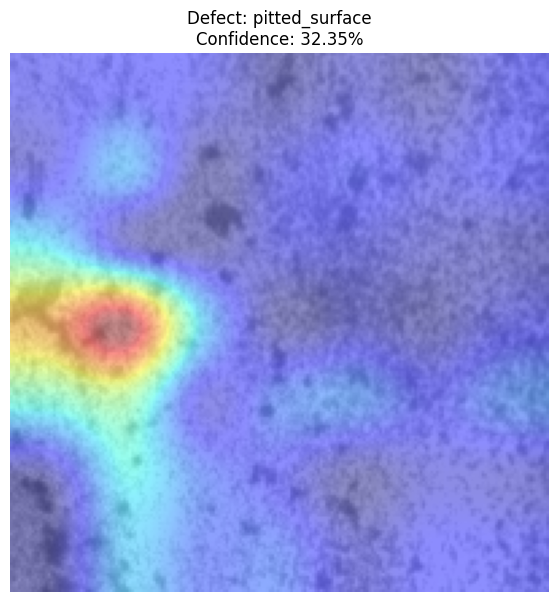

In [ ]:
plt.figure(figsize=(7, 7))

plt.imshow(
    original_image,
    cmap="gray"
)

plt.imshow(
    cam,
    cmap="jet",
    alpha=0.45
)

plt.axis("off")

plt.title(
    f"Defect: {image_result['Predicted Defect']}\n"
    f"Confidence: {image_result['Confidence (%)']}%"
)

plt.show()

# **PART 85 — Test the fusion with the real image + NLP**

In [ ]:
failure_probability = 72.5

rul_prediction = 18

In [ ]:
final_result = integrated_machine_analysis(

    failure_probability,

    rul_prediction,

    image_result,

    critical_nlp
)

In [ ]:
display_final_machine_report(
    final_result
)



           SMART MAINTENANCE AI
           MACHINE HEALTH REPORT

OVERALL MACHINE STATUS:
HIGH RISK

OVERALL RISK:
68.05%

--- SENSOR ANALYSIS ---
Failure Probability: 72.5 %

--- RUL ANALYSIS ---
Predicted RUL: 18.0

--- IMAGE ANALYSIS ---
Detected Defect: pitted_surface
Confidence: 32.35 %

--- MAINTENANCE LOG NLP ---
Detected Fault: Excessive Vibration
Severity: High

--- RECOMMENDATIONS ---
1. Schedule immediate machine inspection.
2. Machine may require maintenance soon based on predicted RUL.
3. Review the reported maintenance issue and perform targeted inspection.




# **TESTING:**

# **PART 86 — Check Your XGBoost Features**

In [ ]:
print("XGBoost model:", type(xgb_model).__name__)

print("\nExpected XGBoost features:")

if hasattr(xgb_model, "feature_names_in_"):
    print(list(xgb_model.feature_names_in_))

elif hasattr(xgb_model, "get_booster"):
    print(
        xgb_model.get_booster().feature_names
    )

else:
    print("Feature names could not be automatically detected.")

XGBoost model: XGBClassifier

Expected XGBoost features:
[np.str_('Air temperature _K_'), np.str_('Process temperature _K_'), np.str_('Rotational speed _rpm_'), np.str_('Torque _Nm_'), np.str_('Tool wear _min_'), np.str_('TWF'), np.str_('HDF'), np.str_('PWF'), np.str_('OSF'), np.str_('RNF'), np.str_('Type_L'), np.str_('Type_M')]


# **PART 87 — Create Machine Input**

In [ ]:
machine_input = {
    "Air temperature [K]": 309.65,
    "Process temperature [K]": 368.15,
    "Rotational speed [rpm]": 1450,
    "Torque [Nm]": 72,
    "Tool wear [min]": 185
}

print(machine_input)

{'Air temperature [K]': 309.65, 'Process temperature [K]': 368.15, 'Rotational speed [rpm]': 1450, 'Torque [Nm]': 72, 'Tool wear [min]': 185}


# **PART 88 — Prepare Input for XGBoost**

In [ ]:
import pandas as pd
import numpy as np

def prepare_xgb_input(machine_input):

    if hasattr(xgb_model, "feature_names_in_"):

        feature_names = list(
            xgb_model.feature_names_in_
        )

    elif hasattr(xgb_model, "get_booster"):

        feature_names = (
            xgb_model
            .get_booster()
            .feature_names
        )

    else:

        raise ValueError(
            "Could not determine XGBoost feature names."
        )

    missing = [
        feature
        for feature in feature_names
        if feature not in machine_input
    ]

    if len(missing) > 0:

        raise ValueError(
            "Missing features:\n"
            + "\n".join(missing)
        )

    X = pd.DataFrame(
        [
            [
                machine_input[feature]
                for feature in feature_names
            ]
        ],
        columns=feature_names
    )

    return X

# **PART 89 — Predict Failure Probability**

In [ ]:
def predict_machine_failure(
    machine_input
):

    X = prepare_xgb_input(
        machine_input
    )

    # Probability of failure
    probabilities = xgb_model.predict_proba(
        X
    )[0]

    # Usually class 1 = failure
    classes = list(
        xgb_model.classes_
    )

    if 1 in classes:

        failure_index = classes.index(1)

    else:

        failure_index = -1

    failure_probability = (
        probabilities[failure_index] * 100
    )

    prediction = xgb_model.predict(
        X
    )[0]

    if prediction == 1:

        failure_status = "FAILURE RISK"

    else:

        failure_status = "NO IMMEDIATE FAILURE"

    return {
        "prediction": int(prediction),
        "failure_probability": float(
            failure_probability
        ),
        "status": failure_status
    }

# **PART 90 — Test XGBoost**

In [ ]:
import pandas as pd
import numpy as np
import re


def clean_feature_name(name):

    # Convert to string
    name = str(name)

    # Replace spaces with _
    name = name.replace(" ", "_")

    # Replace [ with _
    name = name.replace("[", "_")

    # Replace ] with _
    name = name.replace("]", "_")

    # Replace other unwanted characters
    name = re.sub(
        r"[^a-zA-Z0-9_]",
        "_",
        name
    )

    return name


def prepare_xgb_input(machine_input):

    # Get the exact feature names used by XGBoost

    if hasattr(xgb_model, "feature_names_in_"):

        feature_names = list(
            xgb_model.feature_names_in_
        )

    elif hasattr(xgb_model, "get_booster"):

        feature_names = (
            xgb_model
            .get_booster()
            .feature_names
        )

    else:

        raise ValueError(
            "Could not determine XGBoost feature names."
        )

    # Clean the names supplied by us
    cleaned_input = {}

    for key, value in machine_input.items():

        cleaned_key = clean_feature_name(key)

        cleaned_input[cleaned_key] = value

    # Check which model features are missing
    missing = []

    for feature in feature_names:

        if feature not in cleaned_input:

            missing.append(feature)

    if len(missing) > 0:

        print("XGBoost expects these features:")
        print()

        for feature in feature_names:
            print(feature)

        print("\nMissing features:")

        for feature in missing:
            print(feature)

        raise ValueError(
            "\nSome required XGBoost features "
            "are missing from machine_input."
        )

    # Create dataframe in EXACT model order

    X = pd.DataFrame(
        [[
            cleaned_input[feature]
            for feature in feature_names
        ]],
        columns=feature_names
    )

    return X

In [ ]:
print("XGBOOST FEATURES")
print("=" * 50)

if hasattr(xgb_model, "feature_names_in_"):

    for feature in xgb_model.feature_names_in_:
        print(feature)

else:

    for feature in xgb_model.get_booster().feature_names:
        print(feature)

XGBOOST FEATURES
Air temperature _K_
Process temperature _K_
Rotational speed _rpm_
Torque _Nm_
Tool wear _min_
TWF
HDF
PWF
OSF
RNF
Type_L
Type_M


In [ ]:
machine_input = {
    "Air temperature [K]": 309.65,
    "Process temperature [K]": 368.15,
    "Rotational speed [rpm]": 1450,
    "Torque [Nm]": 72,
    "Tool wear [min]": 185
}

In [ ]:
print("EXACT FEATURES REQUIRED BY XGBOOST")
print("=" * 60)

xgb_features = list(xgb_model.feature_names_in_)

for i, feature in enumerate(xgb_features, 1):
    print(i, "->", feature)

print("\nNUMBER OF FEATURES:", len(xgb_features))

EXACT FEATURES REQUIRED BY XGBOOST
1 -> Air temperature _K_
2 -> Process temperature _K_
3 -> Rotational speed _rpm_
4 -> Torque _Nm_
5 -> Tool wear _min_
6 -> TWF
7 -> HDF
8 -> PWF
9 -> OSF
10 -> RNF
11 -> Type_L
12 -> Type_M

NUMBER OF FEATURES: 12


In [ ]:
print("FEATURES CURRENTLY PROVIDED")
print("=" * 60)

for key, value in machine_input.items():
    print(key, "=", value)

print("\nMISSING FEATURES")
print("=" * 60)

cleaned_input = {
    clean_feature_name(key): value
    for key, value in machine_input.items()
}

for feature in xgb_features:

    if feature not in cleaned_input:
        print("MISSING ->", feature)

FEATURES CURRENTLY PROVIDED
Air temperature [K] = 309.65
Process temperature [K] = 368.15
Rotational speed [rpm] = 1450
Torque [Nm] = 72
Tool wear [min] = 185

MISSING FEATURES
MISSING -> Air temperature _K_
MISSING -> Process temperature _K_
MISSING -> Rotational speed _rpm_
MISSING -> Torque _Nm_
MISSING -> Tool wear _min_
MISSING -> TWF
MISSING -> HDF
MISSING -> PWF
MISSING -> OSF
MISSING -> RNF
MISSING -> Type_L
MISSING -> Type_M


In [ ]:
machine_input = {
    "Air temperature [K]": 309.65,
    "Process temperature [K]": 368.15,
    "Rotational speed [rpm]": 1450,
    "Torque [Nm]": 72,
    "Tool wear [min]": 185
}

In [ ]:
machine_input = {
    "Air temperature _K_": 309.65,
    "Process temperature _K_": 368.15,
    "Rotational speed _rpm_": 1450,
    "Torque _Nm_": 72,
    "Tool wear _min_": 185,

    # Failure-mode indicators
    "TWF": 0,
    "HDF": 0,
    "PWF": 0,
    "OSF": 0,
    "RNF": 0,

    # Machine type
    # L = 0, M = 1
    "Type_L": 0,
    "Type_M": 1
}

print("Machine input created successfully.")

Machine input created successfully.


In [ ]:
def prepare_xgb_input(machine_input):

    feature_names = list(
        xgb_model.feature_names_in_
    )

    missing = []

    for feature in feature_names:

        if feature not in machine_input:
            missing.append(feature)

    if len(missing) > 0:

        print("Missing features:")

        for feature in missing:
            print(feature)

        raise ValueError(
            "Some required XGBoost features are missing."
        )

    X = pd.DataFrame(
        [[
            machine_input[feature]
            for feature in feature_names
        ]],
        columns=feature_names
    )

    return X

In [ ]:
sensor_result = predict_machine_failure(
    machine_input
)

print(sensor_result)

{'prediction': 0, 'failure_probability': 0.9275779128074646, 'status': 'NO IMMEDIATE FAILURE'}


In [ ]:
import os
import random

print("Looking for image dataset...")

# Use your existing sample_path if it already exists
if "sample_path" in globals() and os.path.exists(sample_path):

    machine_image = sample_path

else:

    # Search common image folders
    possible_dirs = [
        os.path.join(PROJECT_DIR, "datasets", "raw", "images"),
        os.path.join(PROJECT_DIR, "datasets", "raw", "AI4I"),
        os.path.join(PROJECT_DIR, "images")
    ]

    image_files = []

    for folder in possible_dirs:

        if os.path.exists(folder):

            for root, dirs, files in os.walk(folder):

                for file in files:

                    if file.lower().endswith(
                        (".jpg", ".jpeg", ".png")
                    ):

                        image_files.append(
                            os.path.join(root, file)
                        )

    if len(image_files) == 0:

        raise FileNotFoundError(
            "No images found. Please check your image dataset path."
        )

    machine_image = random.choice(
        image_files
    )

print("Selected machine image:")
print(machine_image)

Looking for image dataset...
Selected machine image:
/content/drive/MyDrive/Smart_Maintenance_AI/datasets/raw/images/NEU_dataset/NEU-DET/validation/images/patches/patches_288.jpg


In [ ]:
image_result, original_image, final_cam = complete_image_analysis(
    machine_image
)

print("\nIMAGE PREDICTION")
print("=" * 50)

print(
    "Predicted Defect:",
    image_result.get(
        "Predicted Defect",
        "Unknown"
    )
)

print(
    "Confidence:",
    image_result.get(
        "Confidence (%)",
        "Unknown"
    ),
    "%"
)


IMAGE PREDICTION
Predicted Defect: patches
Confidence: 42.7 %


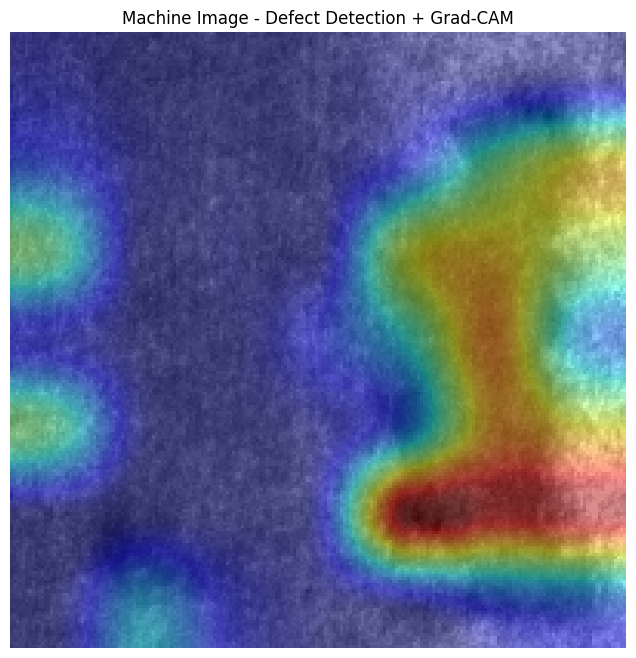

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 8))

plt.imshow(
    original_image,
    cmap="gray"
)

plt.imshow(
    final_cam,
    cmap="jet",
    alpha=0.45
)

plt.axis("off")

plt.title(
    "Machine Image - Defect Detection + Grad-CAM"
)

plt.show()

# **PART 91 — Maintenance Log Input**

In [ ]:
maintenance_log = """
The machine is producing severe vibration and excessive noise
during operation. The bearing temperature has increased significantly
and the rotating shaft is showing abnormal movement. The operator
has noticed signs of bearing wear and overheating. Immediate
inspection is required because the machine may fail if operation
continues.
"""

# **PART 92 — Run NLP Analysis**

In [ ]:
nlp_result = analyze_maintenance_log(
    maintenance_log
)

print("\nNLP ANALYSIS")
print("=" * 50)

print(nlp_result)


NLP ANALYSIS
{'maintenance_log': '\nThe machine is producing severe vibration and excessive noise\nduring operation. The bearing temperature has increased significantly\nand the rotating shaft is showing abnormal movement. The operator\nhas noticed signs of bearing wear and overheating. Immediate\ninspection is required because the machine may fail if operation\ncontinues.\n', 'predicted_fault': 'Excessive Vibration', 'fault_confidence': 58.43, 'severity': 'High', 'keywords': ['noise', 'wear', 'vibration', 'increased', 'temperature', 'excessive', 'normal', 'abnormal', 'severe'], 'recommendation': 'Inspect machine alignment, bearings and rotating components.'}


In [ ]:
display_nlp_result(
    nlp_result
)

MAINTENANCE LOG ANALYSIS

Detected Fault:
Excessive Vibration

Fault Confidence:
58.43%

Severity:
High

Important Keywords:
noise, wear, vibration, increased, temperature, excessive, normal, abnormal, severe

Recommendation:
Inspect machine alignment, bearings and rotating components.


# **PART 93— Check Your RUL Model**

In [ ]:
print("RUL-RELATED VARIABLES")
print("=" * 60)

for name in sorted(globals()):

    if any(
        word in name.lower()
        for word in [
            "rul",
            "lstm",
            "tcn",
            "cmapss"
        ]
    ):

        print(
            name,
            "->",
            type(
                globals()[name]
            ).__name__
        )

RUL-RELATED VARIABLES
CMAPSS_DIR -> str
CMAPSS_EXTRACTED -> str
CMAPSS_EXTRACT_DIR -> str
CMAPSS_ZIP -> str
LSTMModel -> type
MAX_RUL -> int
X_rul -> ndarray
X_rul_train -> ndarray
X_rul_val -> ndarray
cmapss_zips -> list
final_rul -> int64
lstm_model -> LSTMModel
lstm_path -> str
normalize_rul_risk -> function
rul_files -> list
rul_prediction -> int
rul_raw -> DataFrame
rul_results -> DataFrame
rul_risk -> float
rul_scaler -> MinMaxScaler
sample_rul -> int
test_rul_values -> ndarray
train_cmapss -> DataFrame
y_rul -> ndarray
y_rul_train -> ndarray
y_rul_val -> ndarray


In [ ]:
if "rul_prediction" in globals():

    print(
        "RUL prediction already exists:"
    )

    print(
        rul_prediction
    )

else:

    print(
        "rul_prediction does not exist yet."
    )

RUL prediction already exists:
18


# **PART 94 — Root Cause Analysis**

In [ ]:
sensor_result
image_result
nlp_result

{'maintenance_log': '\nThe machine is producing severe vibration and excessive noise\nduring operation. The bearing temperature has increased significantly\nand the rotating shaft is showing abnormal movement. The operator\nhas noticed signs of bearing wear and overheating. Immediate\ninspection is required because the machine may fail if operation\ncontinues.\n',
 'predicted_fault': 'Excessive Vibration',
 'fault_confidence': 58.43,
 'severity': 'High',
 'keywords': ['noise',
  'wear',
  'vibration',
  'increased',
  'temperature',
  'excessive',
  'normal',
  'abnormal',
  'severe'],
 'recommendation': 'Inspect machine alignment, bearings and rotating components.'}

In [ ]:
def generate_root_causes(
    sensor_result,
    image_result,
    nlp_result
):

    causes = []

    # Sensor evidence
    failure_probability = sensor_result.get(
        "failure_probability",
        0
    )

    if failure_probability >= 70:

        causes.append(
            "High predicted machine failure risk"
        )

    elif failure_probability >= 40:

        causes.append(
            "Moderate predicted machine failure risk"
        )

    # Image evidence
    defect = image_result.get(
        "Predicted Defect",
        None
    )

    if defect:

        causes.append(
            "Visible machine defect: "
            + str(defect)
        )

    # NLP evidence
    fault = nlp_result.get(
        "predicted_fault",
        None
    )

    if fault:

        causes.append(
            "Maintenance-log indication: "
            + str(fault)
        )

    if len(causes) == 0:

        causes.append(
            "No dominant root cause identified"
        )

    return causes

In [ ]:
root_causes = generate_root_causes(
    sensor_result,
    image_result,
    nlp_result
)

print("\nROOT CAUSE ANALYSIS")
print("=" * 50)

for cause in root_causes:

    print(
        "•",
        cause
    )


ROOT CAUSE ANALYSIS
• Visible machine defect: patches
• Maintenance-log indication: Excessive Vibration


# **PART 95 — Run Multimodal Fusion**

In [ ]:
final_result = integrated_machine_analysis(

    sensor_result[
        "failure_probability"
    ],

    rul_prediction,

    image_result,

    nlp_result
)

In [ ]:
print("\nMULTIMODAL FUSION RESULT")
print("=" * 50)

print(final_result)


MULTIMODAL FUSION RESULT
{'machine_status': 'CRITICAL', 'overall_risk_percentage': 75.09, 'sensor_failure_probability': 0.93, 'predicted_RUL': 18.0, 'image_defect': 'patches', 'image_confidence': 42.7, 'NLP_fault': 'Excessive Vibration', 'NLP_severity': 'High', 'recommendations': ['Schedule immediate machine inspection.', 'Machine may require maintenance soon based on predicted RUL.', 'Review the reported maintenance issue and perform targeted inspection.']}


# **PART 96 — Create the Complete Final Report**

In [ ]:
def display_complete_machine_report(
    sensor_result,
    rul_prediction,
    image_result,
    nlp_result,
    root_causes,
    final_result
):

    print("\n")
    print("=" * 75)
    print("              SMART MAINTENANCE AI")
    print("              MACHINE HEALTH REPORT")
    print("=" * 75)

    # -------------------------------
    # SENSOR
    # -------------------------------

    print("\n[SENSOR ANALYSIS]")
    print("-" * 75)

    print(
        "Failure Prediction :",
        sensor_result.get(
            "status",
            "Unknown"
        )
    )

    print(
        "Failure Probability:",
        round(
            float(
                sensor_result[
                    "failure_probability"
                ]
            ),
            2
        ),
        "%"
    )

    # -------------------------------
    # RUL
    # -------------------------------

    print("\n[RUL ANALYSIS]")
    print("-" * 75)

    print(
        "Remaining Useful Life:",
        round(
            float(rul_prediction),
            2
        ),
        "cycles"
    )

    # -------------------------------
    # IMAGE
    # -------------------------------

    print("\n[IMAGE ANALYSIS]")
    print("-" * 75)

    print(
        "Detected Defect:",
        image_result.get(
            "Predicted Defect",
            "Unknown"
        )
    )

    print(
        "Confidence:",
        image_result.get(
            "Confidence (%)",
            "Unknown"
        ),
        "%"
    )

    print(
        "Grad-CAM: Available"
    )

    # -------------------------------
    # NLP
    # -------------------------------

    print("\n[MAINTENANCE LOG NLP]")
    print("-" * 75)

    print(
        "Detected Fault:",
        nlp_result.get(
            "predicted_fault",
            "Unknown"
        )
    )

    print(
        "Severity:",
        nlp_result.get(
            "severity",
            "Unknown"
        )
    )

    keywords = nlp_result.get(
        "keywords",
        []
    )

    print(
        "Keywords:",
        ", ".join(
            map(str, keywords)
        )
        if keywords
        else "None"
    )

    # -------------------------------
    # ROOT CAUSE
    # -------------------------------

    print("\n[ROOT CAUSE ANALYSIS]")
    print("-" * 75)

    for cause in root_causes:

        print(
            "•",
            cause
        )

    # -------------------------------
    # FINAL FUSION
    # -------------------------------

    print("\n[FINAL MULTIMODAL ASSESSMENT]")
    print("-" * 75)

    # Handle different possible names
    status = final_result.get(
        "machine_status",
        final_result.get(
            "status",
            "Unknown"
        )
    )

    risk = final_result.get(
        "overall_risk_percentage",
        final_result.get(
            "overall_risk",
            "Unknown"
        )
    )

    print(
        "Overall Machine Status:",
        status
    )

    print(
        "Overall Risk:",
        risk,
        "%"
        if isinstance(
            risk,
            (int, float)
        )
        else ""
    )

    # -------------------------------
    # RECOMMENDATIONS
    # -------------------------------

    print("\n[MAINTENANCE RECOMMENDATIONS]")
    print("-" * 75)

    recommendations = final_result.get(
        "recommendations",
        []
    )

    if isinstance(
        recommendations,
        list
    ):

        for i, recommendation in enumerate(
            recommendations,
            1
        ):

            print(
                f"{i}. {recommendation}"
            )

    else:

        print(
            recommendations
        )

    print("\n")
    print("=" * 75)
    print("                  END OF REPORT")
    print("=" * 75)

# **PART 97 — RUN THE COMPLETE REPORT**

In [ ]:
display_complete_machine_report(

    sensor_result,

    rul_prediction,

    image_result,

    nlp_result,

    root_causes,

    final_result
)



              SMART MAINTENANCE AI
              MACHINE HEALTH REPORT

[SENSOR ANALYSIS]
---------------------------------------------------------------------------
Failure Prediction : NO IMMEDIATE FAILURE
Failure Probability: 0.93 %

[RUL ANALYSIS]
---------------------------------------------------------------------------
Remaining Useful Life: 18.0 cycles

[IMAGE ANALYSIS]
---------------------------------------------------------------------------
Detected Defect: patches
Confidence: 42.7 %
Grad-CAM: Available

[MAINTENANCE LOG NLP]
---------------------------------------------------------------------------
Detected Fault: Excessive Vibration
Severity: High
Keywords: noise, wear, vibration, increased, temperature, excessive, normal, abnormal, severe

[ROOT CAUSE ANALYSIS]
---------------------------------------------------------------------------
• Visible machine defect: patches
• Maintenance-log indication: Excessive Vibration

[FINAL MULTIMODAL ASSESSMENT]
-------------------

# **SAVE EVERYTHING**

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
import os

PROJECT_DIR = "/content/drive/MyDrive/Smart_Maintenance_AI"

os.makedirs(PROJECT_DIR, exist_ok=True)

os.makedirs(
    os.path.join(PROJECT_DIR, "models"),
    exist_ok=True
)

os.makedirs(
    os.path.join(PROJECT_DIR, "preprocessing"),
    exist_ok=True
)

os.makedirs(
    os.path.join(PROJECT_DIR, "results"),
    exist_ok=True
)

os.makedirs(
    os.path.join(PROJECT_DIR, "reports"),
    exist_ok=True
)

os.makedirs(
    os.path.join(PROJECT_DIR, "predictions"),
    exist_ok=True
)

print("Project folders created successfully.")
print(PROJECT_DIR)

Project folders created successfully.
/content/drive/MyDrive/Smart_Maintenance_AI


In [ ]:
xgb_path = os.path.join(
    PROJECT_DIR,
    "models",
    "xgboost_failure_model.json"
)

xgb_model.save_model(xgb_path)

print("XGBoost model saved:")
print(xgb_path)

XGBoost model saved:
/content/drive/MyDrive/Smart_Maintenance_AI/models/xgboost_failure_model.json


In [ ]:
import json

xgb_features_path = os.path.join(
    PROJECT_DIR,
    "preprocessing",
    "xgboost_features.json"
)

with open(
    xgb_features_path,
    "w"
) as f:

    json.dump(
        list(xgb_model.feature_names_in_),
        f,
        indent=4
    )

print("XGBoost feature names saved.")

XGBoost feature names saved.


In [ ]:
rul_model_path = os.path.join(
    PROJECT_DIR,
    "models",
    "cmapss_lstm_rul.pth"
)

torch.save(
    lstm_model.state_dict(),
    rul_model_path
)

print("LSTM RUL model saved.")

LSTM RUL model saved.


In [ ]:
import joblib

rul_scaler_path = os.path.join(
    PROJECT_DIR,
    "preprocessing",
    "cmapss_rul_scaler.pkl"
)

joblib.dump(
    rul_scaler,
    rul_scaler_path
)

print("RUL scaler saved.")

RUL scaler saved.


In [ ]:
image_model_path = os.path.join(
    PROJECT_DIR,
    "models",
    "machine_image_model.pth"
)

torch.save(
    image_model.state_dict(),
    image_model_path
)

print("Image model saved.")

Image model saved.


In [ ]:
image_classes = None

if "class_names" in globals():
    image_classes = class_names

elif "classes" in globals():
    image_classes = classes

else:
    image_classes = [
        "Normal",
        "Defective"
    ]

with open(
    os.path.join(
        PROJECT_DIR,
        "preprocessing",
        "image_classes.json"
    ),
    "w"
) as f:

    json.dump(
        list(image_classes),
        f,
        indent=4
    )

print("Image class names saved.")

Image class names saved.


In [ ]:
import numpy as np
import torch
import json


def make_json_serializable(obj):

    if isinstance(
        obj,
        (
            np.integer,
            np.int32,
            np.int64
        )
    ):
        return int(obj)

    if isinstance(
        obj,
        (
            np.floating,
            np.float32,
            np.float64
        )
    ):
        return float(obj)

    if isinstance(
        obj,
        np.ndarray
    ):
        return obj.tolist()

    if torch.is_tensor(obj):

        if obj.numel() == 1:
            return float(obj.detach().cpu().item())

        return obj.detach().cpu().tolist()

    if isinstance(obj, dict):

        return {
            str(k): make_json_serializable(v)
            for k, v in obj.items()
        }

    if isinstance(obj, list):

        return [
            make_json_serializable(v)
            for v in obj
        ]

    if isinstance(obj, tuple):

        return [
            make_json_serializable(v)
            for v in obj
        ]

    return obj

In [ ]:
complete_report = {

    "sensor_analysis":
        sensor_result,

    "rul_prediction":
        rul_prediction,

    "image_analysis":
        image_result,

    "nlp_analysis":
        nlp_result,

    "root_cause_analysis":
        root_causes,

    "final_multimodal_assessment":
        final_result
}

In [ ]:
complete_report = make_json_serializable(
    complete_report
)

In [ ]:
report_path = os.path.join(
    PROJECT_DIR,
    "reports",
    "complete_machine_report.json"
)

with open(
    report_path,
    "w"
) as f:

    json.dump(
        complete_report,
        f,
        indent=4
    )

print("Complete machine report saved.")
print(report_path)

Complete machine report saved.
/content/drive/MyDrive/Smart_Maintenance_AI/reports/complete_machine_report.json


In [ ]:
report_txt_path = os.path.join(
    PROJECT_DIR,
    "reports",
    "complete_machine_report.txt"
)

with open(
    report_txt_path,
    "w"
) as f:

    f.write(
        "SMART MAINTENANCE AI\n"
    )

    f.write(
        "=" * 70 + "\n\n"
    )

    f.write(
        "SENSOR ANALYSIS\n"
    )

    f.write(
        "-" * 70 + "\n"
    )

    f.write(
        str(sensor_result) + "\n\n"
    )

    f.write(
        "REMAINING USEFUL LIFE\n"
    )

    f.write(
        "-" * 70 + "\n"
    )

    f.write(
        f"{rul_prediction} cycles\n\n"
    )

    f.write(
        "IMAGE ANALYSIS\n"
    )

    f.write(
        "-" * 70 + "\n"
    )

    f.write(
        str(image_result) + "\n\n"
    )

    f.write(
        "NLP ANALYSIS\n"
    )

    f.write(
        "-" * 70 + "\n"
    )

    f.write(
        str(nlp_result) + "\n\n"
    )

    f.write(
        "ROOT CAUSE ANALYSIS\n"
    )

    f.write(
        "-" * 70 + "\n"
    )

    for cause in root_causes:

        f.write(
            "• " + str(cause) + "\n"
        )

    f.write("\n")

    f.write(
        "FINAL MULTIMODAL ASSESSMENT\n"
    )

    f.write(
        "-" * 70 + "\n"
    )

    f.write(
        str(final_result) + "\n"
    )

print("Human-readable report saved.")
print(report_txt_path)

Human-readable report saved.
/content/drive/MyDrive/Smart_Maintenance_AI/reports/complete_machine_report.txt


In [ ]:
prediction_record = {

    "machine_input":
        machine_input,

    "sensor_result":
        sensor_result,

    "rul_prediction":
        rul_prediction,

    "image":
        machine_image,

    "image_result":
        image_result,

    "maintenance_log":
        maintenance_log,

    "nlp_result":
        nlp_result,

    "root_causes":
        root_causes,

    "final_result":
        final_result
}

In [ ]:
prediction_record = make_json_serializable(
    prediction_record
)

prediction_path = os.path.join(
    PROJECT_DIR,
    "predictions",
    "sample_prediction.json"
)

with open(
    prediction_path,
    "w"
) as f:

    json.dump(
        prediction_record,
        f,
        indent=4
    )

print("Prediction saved.")
print(prediction_path)

Prediction saved.
/content/drive/MyDrive/Smart_Maintenance_AI/predictions/sample_prediction.json


In [ ]:
print("=" * 60)
print("SMART MAINTENANCE AI - SAVED FILES")
print("=" * 60)

for root, dirs, files in os.walk(PROJECT_DIR):

    level = root.replace(
        PROJECT_DIR,
        ""
    ).count(os.sep)

    indent = "    " * level

    print(
        indent +
        os.path.basename(root) +
        "/"
    )

    for file in files:

        print(
            indent +
            "    " +
            file
        )

print("=" * 60)
print("PROJECT SAVED SUCCESSFULLY")
print("=" * 60)

SMART MAINTENANCE AI - SAVED FILES
Smart_Maintenance_AI/
    datasets/
        raw/
            AI4I/
                ai4i+2020+predictive+maintenance+dataset.zip
                extracted/
                    ai4i2020.csv
            C-MAPSS/
                CMAPSSData.zip
                extracted/
                    Damage Propagation Modeling.pdf
                    readme.txt
                    RUL_FD001.txt
                    RUL_FD002.txt
                    RUL_FD003.txt
                    RUL_FD004.txt
                    test_FD001.txt
                    test_FD002.txt
                    test_FD003.txt
                    test_FD004.txt
                    train_FD001.txt
                    train_FD002.txt
                    train_FD003.txt
                    train_FD004.txt
            images/
                archive (1).zip
                NEU_dataset/
                    NEU-DET/
                        train/
                            annotations/
             